# Parametric insurance: design, evaluate and compare covers

This tutorial shows how to design parametric insurance covers with `climada_petals.engine.parametric`, how to evaluate them and how to compare them, on CLIMADA's own objects: a `Hazard`, `Exposures`, impact functions and an `Impact`.

It is written for a new user, in three parts:

1. **What parametric insurance is** (section 1), and how it differs from CLIMADA's indemnity layer and from `cat_bonds`.
2. **How the module works** (sections 2 to 4): a small example built in memory, which runs in seconds, the payout families, and the methods behind a design.
3. **What it makes possible** (sections 5 to 16): tropical cyclones in Jamaica and windstorms in Luxembourg, on data from the CLIMADA Data API, through units and indices, objectives, budgets, scopes, basis risk, short records and climate scenarios, to user extensions and `cat_bonds`.

Contents:

1. What parametric insurance is
2. How the module works: a small example in memory
3. Payout functions
4. What a design computes: bases, objectives, solvers
5. Jamaica: data from the CLIMADA Data API, units and indices
6. Three objectives at one budget
7. The budget frontier
8. A free attachment, and the ranges of a design
9. The calibration scope
10. Out-of-sample evaluation and CLIMADA objects
11. Basis risk
12. A short record: 41 observed years, evaluated on STORM
13. Climate scenarios
14. A second hazard: windstorm in Luxembourg
15. Extending the module: a payout and an objective of your own
16. Working with `cat_bonds`

**Data and runtime.** All data come from the [CLIMADA Data API](https://climada.ethz.ch/data-api/) through `climada.util.api_client.Client`, with no credentials: Jamaica's LitPop and tropical cyclone sets (STORM, `random_walk` with its rcp 4.5 futures, and the observed storms), and Luxembourg's LitPop and windstorm set. The first run downloads about 205 MB into CLIMADA's data folder, 164 MB of which is STORM. Section 5 prints each dataset's version and licence. From a fresh kernel, the whole notebook ran in about 30 seconds on a laptop with the files in CLIMADA's cache, and in about 35 seconds on a first run that downloaded them over a fast connection; the download time depends on the connection. The last cell prints the time of the run. Two subsets are taken, each stated where it is made: the events of STORM's global set that bring no wind to Jamaica are left out, which changes no number, and sections 5 and 11 use one point of the exposures as an insured unit.

**How to read the numbers.** Every table of metrics comes with its setup: the insured units, the basis and route, the index (which is where basis risk comes from), the pricing and premium, and the split. `setup_text` prints it under each table. The numbers are from out-of-sample evaluations on the annual basis. They describe the stated setup only: none of them says that one objective, or one calibration scope, is better in general.

## 1. What parametric insurance is

An **indemnity** cover pays what the insured lost, as assessed after the event. CLIMADA has one: `Impact.calc_risk_transfer(attachment, cover)` takes each event's total loss and pays the part above an attachment, up to a cover.

A **parametric** cover pays on an **index** instead: a measured or modelled quantity of the event, such as the wind speed over a region, the category a storm reaches within a circle, rainfall at a station or ground shaking. A **payout function**, fixed in the contract, turns the index into a payout. Nothing is assessed after the event, so the cover can pay within days, and its terms are transparent. The price is **basis risk**: the payout follows the index, not the loss. An event can cause a loss and pay little or nothing (a false negative), or pay without a loss (a false positive).

**Designing** a cover means choosing the index, the payout function and its parameters, so that the payouts track the losses in the way the owner needs, within a premium budget. **Evaluating** a cover means measuring how well they track: on average, in the worst years, and how often they miss.

**Next to `cat_bonds`.** `climada_petals.engine.cat_bonds` designs parametric cat bonds for a sovereign: a linear payout per subarea of a country, its two triggers fitted by COBYLA to the squared error between payout and loss, then the pooling of countries into bonds and their pricing. This module designs covers for one risk owner, with any payout family and one of several objectives, one design problem per unit or one for all units together, and it evaluates any cover on any sample. Section 16 shows how the two fit together.

The terms used throughout:

| Term | In the module | What it is |
|---|---|---|
| Insured unit | `InsuredUnits` | The exposure points that share one payout function: one point, a region, the whole country |
| Index | `ParametricIndex`, `IndexDefinition` | The value the cover pays on, per event and unit, and how it is computed |
| Payout function | `StepPayout`, `LinearPayout`, `PiecewiseLinearPayout`, `BinaryPayout` | Turns an index value into a payout. Nothing is paid below its first threshold |
| Cover | `ParametricCover` | The terms of the contract: the index definition, a payout function per unit, the payout unit, and a `Limit` (the most one event pays at one unit). A cover with a `Free` parameter is a **template** |
| Basis | `EventBasis`, `CatalogueYears`, `YearSets` | What one outcome is: an event, or a simulated year |
| Sample | `OutcomeSample` | An index, the loss per unit and a basis, joined |
| Objective | `MSE`, `ExpectedUncovered`, `WeightedCVaR`, `UserObjective` | What a design minimises |
| Scope | `scope="individual"` or `scope="joint"` | One design problem per unit, or one for the owner's total |
| Pricing and budget | `PurePremium`, `CostOfCapitalLoad`, `Budget` | The premium, and the most it may be |
| Design | `calibrate`, which returns a `CalibrationResult` | The resolved cover, and how it was found |
| Evaluation | `evaluate`, `compare` | Tables of metrics, with the setup in columns |

In [1]:
import logging
import tempfile
import time
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Any, ClassVar

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import xarray as xr
from climada.engine import ImpactCalc
from climada.entity import Exposures, ImpactFuncSet, ImpfTropCyclone
from climada.entity.impact_funcs.storm_europe import ImpfStormEurope
from climada.entity.impact_funcs.trop_cyclone import ImpfSetTropCyclone
from climada.hazard import Centroids, TCTracks, TropCyclone
from climada.hazard.tc_tracks import SAFFIR_SIM_CAT
from climada.util import log_level
from climada.util.api_client import Client
from shapely.geometry import box

from climada_petals.engine import parametric as pm
from climada_petals.engine.cat_bonds.subareas import Subareas

START = time.perf_counter()

CLIMADA logs every file it reads, with its path on your machine. The next cell keeps CLIMADA's messages to warnings, and drops the timestamps from the log lines. The module's own warnings stay on: some of them change how a number should be read.

The helper `view` picks columns of a table of metrics and shows the amounts of money in million USD. It is for display only.

In [2]:
logging.getLogger("climada").setLevel(logging.WARNING)
for name in ("climada", "climada_petals"):
    for handler in logging.getLogger(name).handlers:
        handler.setFormatter(logging.Formatter("%(levelname)s %(name)s: %(message)s"))
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 80)

KEYS = ("cover_label", "level", "unit_id")


def view(table, columns, money=(), keys=KEYS):
    """Return some columns of a table of metrics, with money in million USD."""
    shown = table[[*keys, *columns]].copy()
    for column in money:
        shown[column] = shown[column] / 1e6
    shown = shown.rename(columns={column: f"{column} [M USD]" for column in money})
    return shown.round(3).reset_index(drop=True)

## 2. How the module works: a small example in memory

The whole chain on objects built in memory: a fictitious island of twelve exposure points in two districts, 300 years of synthetic storms that move west across it, the wind field of each storm, and the impact. Nothing is downloaded.

### 2.1 Hazard, exposures and impact

The exposures are a grid of twelve points with random values. Each storm's track is a straight line at a random latitude, with a random maximum wind; `TropCyclone.from_tracks` computes its wind field at the exposure points. `ignore_distance_to_coast=True` skips the distance to the coast, which CLIMADA would otherwise read from a file it downloads.

In [3]:
rng = np.random.default_rng(2026)
N_YEARS = 300

lat, lon = np.meshgrid(
    np.linspace(15.0, 15.3, 3), np.linspace(-61.0, -60.4, 4), indexing="ij"
)
island = Exposures(
    lat=lat.ravel(),
    lon=lon.ravel(),
    value=rng.lognormal(np.log(2e8), 0.6, lat.size),
    value_unit="USD",
)
island.gdf["impf_TC"] = 1
island.gdf["district"] = np.where(island.longitude < -60.7, "west", "east")


def straight_track(name, year, latitude, wind_kn, n_points=25):
    """Return a synthetic track moving west near a latitude, 3 hours a step."""
    times = np.datetime64(f"{2000 + year}-09-01") + np.arange(
        n_points
    ) * np.timedelta64(3, "h")
    constant = lambda value: ("time", np.full(n_points, value))
    return xr.Dataset(
        {
            "time_step": constant(3.0),
            "radius_max_wind": constant(25.0),
            "radius_oci": constant(200.0),
            "max_sustained_wind": constant(wind_kn),
            "central_pressure": constant(1010.0 - 0.9 * wind_kn),
            "environmental_pressure": constant(1010.0),
            "basin": constant("NA"),
        },
        coords={
            "time": ("time", times),
            "lat": ("time", latitude + np.linspace(-0.6, 0.6, n_points)),
            "lon": ("time", np.linspace(-56.0, -66.0, n_points)),
        },
        attrs={
            "max_sustained_wind_unit": "kn",
            "central_pressure_unit": "hPa",
            "name": name,
            "sid": name,
            "orig_event_flag": True,
            "data_provider": "synthetic",
            "id_no": 0,
            "category": 0,
        },
    )


tracks = TCTracks(
    [
        straight_track(
            f"Y{year:03d}_{k}", year, rng.uniform(13.0, 17.5), rng.gamma(4.0, 20.0)
        )
        for year in range(N_YEARS)
        for k in range(rng.poisson(1.0))
    ]
)
centroids = Centroids(lat=island.latitude, lon=island.longitude)
hazard = TropCyclone.from_tracks(
    tracks, centroids=centroids, ignore_distance_to_coast=True
)
# 300 simulated years, those without a storm included: each storm occurs 1 / 300 per year.
hazard.frequency = np.full(hazard.size, 1.0 / N_YEARS)
impact = ImpactCalc(
    island, ImpactFuncSet([ImpfTropCyclone.from_emanuel_usa()]), hazard
).impact(save_mat=True)
print(
    f"{hazard.size} storms in {N_YEARS} years, {np.count_nonzero(impact.at_event)} with a loss"
)

326 storms in 300 years, 260 with a loss


`save_mat=True` keeps the loss of every event at every exposure point (`impact.imp_mat`). The module needs it: a cover pays per event and unit, so it needs the loss per event and unit.

### 2.2 Units, index and sample

- **Units.** Each district is one insured unit, with one payout function: `InsuredUnits.from_column` groups the points by a column of `Exposures.gdf`. A unit's loss is `imp_mat` summed over its points.
- **Index.** `ParametricIndex.from_hazard` computes one value per event and unit from the hazard's intensity at the unit's centroids. Here `index_stat="max"`: the highest wind over the district. Events are matched on `event_id`, never by position.
- **Basis.** The basis says what one outcome is. Here it is a simulated year: the track names carry the year (`Y017_0` is the first storm of year 17), so `CatalogueYears.from_event_names` reads the years from them.
- **Sample.** `OutcomeSample.from_impact` joins the index, the loss per unit and the basis. It keeps the events with a loss or a non-zero index at some unit; the others can't change any outcome, and they are counted, not dropped silently.
- **Split.** `holdout` splits the sample into a design side and a test side. On catalogue years it cuts contiguous years: the first 70 % design the cover, the last 30 % test it.

In [4]:
units = pm.InsuredUnits.from_column(island, "district")
index = pm.ParametricIndex.from_hazard(hazard, units, index_stat="max")
years = pm.CatalogueYears.from_event_names(
    hazard, r"Y(?P<year>[0-9]+)_[0-9]+", n_years=N_YEARS, first_year=0
)
sample = pm.OutcomeSample.from_impact(index, impact, units=units, basis=years)
train, test = pm.holdout(sample, train_fraction=0.7)

print("units:", units.unit_id)
print("index:", index.definition)
print(f"sample: {sample.n_events} events kept, {sample.n_left_out} left out")
print(f"design side: {train.n_years} years; test side: {test.n_years} years")

INFO climada_petals: outcome sample: 15 of 326 events have no loss and an index of 0 at every unit, and are left out


units: ('east', 'west')
index: IndexDefinition(kind='hazard', unit='m/s', tail='upper', index_stat='max', weight=None, source=None, parameters=mappingproxy({'haz_type': 'TC'}))
sample: 311 events kept, 15 left out
design side: 210 years; test side: 90 years


### 2.3 A cover with fixed terms

A `ParametricCover` holds the terms of a contract and nothing else: the index definition, one payout function per unit, the unit of the payouts, and optionally a `Limit`. Here every district gets the same step payout: 20 million USD from 30 m/s of wind, 80 million from 40 m/s and 250 million from 50 m/s.

`evaluate` computes its metrics on a sample. This cover was not designed on any sample, so for it every sample is out of sample. Its premium is priced on the evaluation sample, under the pure premium (the expected payout), and the table says so in its `premium_basis` column. Each row is a **subject**: a unit's own cover, or the owner's total over the units. The warning it logs is explained in section 2.4.

WARNING climada_petals: evaluate: at 2 of 2 units, e.g. ['east', 'west'], the index determines the loss almost one-to-one (the loss is a non-decreasing function of the index within 1e-06 of its largest value, or the frequency-weighted Spearman correlation of index and loss is at least 0.99, oriented by the index's tail), so a cover can replicate the loss and basis risk reads close to zero. Basis risk needs a stated source: an index from another hazard set or resolution, a statistic over a group of points, a track-based trigger, a table of readings, or impact-function draws. The comonotone_index column marks these units


,cover_label,level,unit_id,expected_loss [M USD],expected_payout [M USD],coverage_ratio,payout_frequency
0,given,unit,east,55.322,52.000,0.699,0.400
1,given,unit,west,43.847,51.556,0.772,0.400
2,given,total,None,99.169,103.556,0.732,0.411


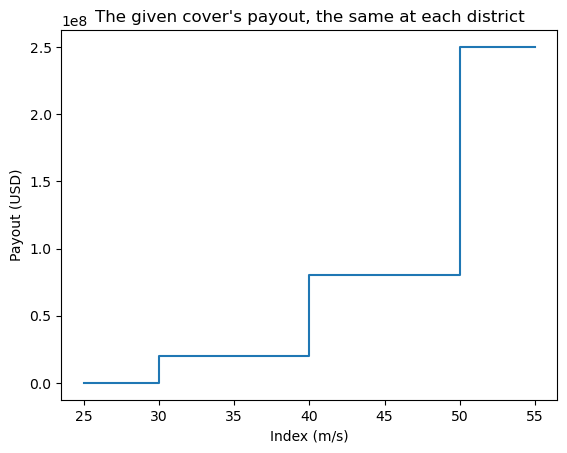

In [5]:
given = pm.ParametricCover(
    index.definition,
    pm.StepPayout([30.0, 40.0, 50.0], [2e7, 8e7, 2.5e8]),
    unit_id=units.unit_id,
    payout_unit="USD",
    label="given",
)
axis = pm.plot_payout(given, "west")
axis.set_title("The given cover's payout, the same at each district")

table = pm.evaluate(given, test, split="out_of_sample")
view(
    table,
    ["expected_loss", "expected_payout", "coverage_ratio", "payout_frequency"],
    money=["expected_loss", "expected_payout"],
)

In [6]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 90 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: max, in m/s; haz_type=TC
Pricing: pure; premium: priced on this sample
Scope: a cover given as it is
Rows: each unit's own cover; the owner's total over the units; units east, west
Payout threshold: 0


`coverage_ratio` is $E[\min(\pi, L)] / E[L]$, the share of the expected loss the payouts cover, and `payout_frequency` the probability of a year with a payout. Section 6 lists the other metrics.

### 2.4 A template, a design and its evaluation

A **template** is a cover with `Free` parameters. `StepPayout.uniform(30, 60, 3)` has steps from 30 m/s, 10 m/s apart, and leaves their levels free. `Limit.largest_loss()` caps every level at the unit's largest event loss on the design sample.

`calibrate` chooses the free parameters on the design side. Here it minimises the expected uncovered loss, `ExpectedUncovered()`, with one design problem per district (`scope="individual"`), under a budget: the pure premium may be at most half the district's expected loss, `Budget(ratio=0.5)`. It returns a `CalibrationResult`: the resolved cover in `result.cover`, and how it was found.

In [7]:
template = pm.ParametricCover(
    index.definition,
    pm.StepPayout.uniform(attachment=30.0, exhaustion=60.0, n_steps=3),
    unit_id=units.unit_id,
    payout_unit="USD",
    limit=pm.Limit.largest_loss(),
    label="E[U] design",
)
print("template:", template.is_resolved, template.free_parameters())
design = pm.calibrate(
    template,
    train,
    pm.ExpectedUncovered(),
    scope="individual",
    budget=pm.Budget(ratio=0.5),
)
design.parameters_frame()

template: False (('east', 'levels[0]'), ('east', 'levels[1]'), ('east', 'levels[2]'), ('west', 'levels[0]'), ('west', 'levels[1]'), ('west', 'levels[2]'))
WARNING climada_petals: calibrate: at 2 of 2 units, e.g. ['east', 'west'], the index determines the loss almost one-to-one (the loss is a non-decreasing function of the index within 1e-06 of its largest value, or the frequency-weighted Spearman correlation of index and loss is at least 0.99, oriented by the index's tail), so a cover can replicate the loss and basis risk reads close to zero. Basis risk needs a stated source: an index from another hazard set or resolution, a statistic over a group of points, a track-based trigger, a table of readings, or impact-function draws. The comonotone_index column marks these units


INFO climada_petals: design problem 'east': expected_uncovered = 5.59788e+07, premium 5.44892e+07 (scipy-highs, highs, 0.00 s)


INFO climada_petals: design problem 'west': expected_uncovered = 4.34659e+07, premium 4.16319e+07 (scipy-highs, highs, 0.00 s)


,unit_id,parameter,value,role,calibrated,unidentified
0,east,breakpoints[0],3.000000e+01,shape,False,False
1,east,breakpoints[1],4.000000e+01,shape,False,False
2,east,breakpoints[2],5.000000e+01,shape,False,False
3,east,levels[0],1.870064e+06,amount,True,False
4,east,levels[1],3.904789e+07,amount,True,False
5,east,levels[2],1.616938e+08,amount,True,False
6,west,breakpoints[0],3.000000e+01,shape,False,False
7,west,breakpoints[1],4.000000e+01,shape,False,False
8,west,breakpoints[2],5.000000e+01,shape,False,False
9,west,levels[0],1.108274e+06,amount,True,False


The calibration logged a warning: in both districts the highest wind determines the loss almost one-to-one. Six points close together share one wind field, so the district's loss is close to a function of its highest wind, and a cover could almost replicate it: basis risk would read close to zero. The `comonotone_index` column of every table marks such units. Section 11 is about this.

The design is evaluated on the test side, out of sample. Its premium is the **design premium**, priced on the design side: it is the price of the contract. Section 10 shows that an out-of-sample evaluation on a sample that shares the design's years raises an error.

In [8]:
table = pm.evaluate(design, test, split="out_of_sample")
view(
    table,
    [
        "expected_loss",
        "premium",
        "expected_payout",
        "coverage_ratio",
        "comonotone_index",
    ],
    money=["expected_loss", "premium", "expected_payout"],
)

WARNING climada_petals: evaluate: at 2 of 2 units, e.g. ['east', 'west'], the index determines the loss almost one-to-one (the loss is a non-decreasing function of the index within 1e-06 of its largest value, or the frequency-weighted Spearman correlation of index and loss is at least 0.99, oriented by the index's tail), so a cover can replicate the loss and basis risk reads close to zero. Basis risk needs a stated source: an index from another hazard set or resolution, a statistic over a group of points, a track-based trigger, a table of readings, or impact-function draws. The comonotone_index column marks these units


,cover_label,level,unit_id,expected_loss [M USD],premium [M USD],expected_payout [M USD],coverage_ratio,comonotone_index
0,E[U] design,unit,east,55.322,54.489,28.917,0.498,True
1,E[U] design,unit,west,43.847,41.632,21.565,0.471,True
2,E[U] design,total,None,99.169,96.121,50.482,0.497,True


In [9]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 90 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: max, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units east, west
Payout threshold: 0


### 2.5 Another index: cat-in-a-circle

A cover can pay on any index. `ParametricIndex.from_cat_in_circle` reads the **tracks**, not the wind field: the highest Saffir-Simpson category a storm reaches within a radius of any point of the unit (Steinmann et al., 2023). The loss comes from the wind field, so index and loss are different things, as in many real contracts. A storm whose track passes outside the circle has the index 0 and can't pay, whatever its wind at the points.

`index_diagnostics` measures how far the index determines the loss, per unit: the Spearman correlation of index and loss over the events with either, whether the loss is a non-decreasing function of the index (`monotone_gap`), and the share of the expected loss on events with an index of 0.

In [10]:
circle = pm.ParametricIndex.from_cat_in_circle(
    tracks, units, hazard=hazard, radius_km=50.0
)
circle_sample = pm.OutcomeSample.from_impact(circle, impact, units=units, basis=years)
diagnostics = pd.concat(
    [
        pm.index_diagnostics(sample).assign(index="highest wind"),
        pm.index_diagnostics(circle_sample).assign(index="cat-in-a-circle, 50 km"),
    ]
)
diagnostics[
    [
        "index",
        "unit_id",
        "spearman",
        "monotone_gap",
        "comonotone_index",
        "zero_index_loss_share",
    ]
].round(3)

INFO climada_petals: outcome sample: 66 of 326 events have no loss and an index of 0 at every unit, and are left out


,index,unit_id,spearman,monotone_gap,comonotone_index,zero_index_loss_share
0,highest wind,east,0.996,0.140,True,0.000
1,highest wind,west,0.997,0.141,True,0.000
0,"cat-in-a-circle, 50 km",east,0.605,0.889,False,0.410
1,"cat-in-a-circle, 50 km",west,0.622,0.879,False,0.383


On this synthetic island, the cat-in-a-circle index leaves a sizeable share of the expected loss on events it reads as 0. A step cover on the category, designed and evaluated as above:

In [11]:
circle_train, circle_test = pm.holdout(circle_sample, train_fraction=0.7)
circle_template = pm.ParametricCover(
    circle.definition,
    pm.StepPayout.uniform(attachment=1.0, exhaustion=6.0, n_steps=5),
    unit_id=units.unit_id,
    payout_unit="USD",
    limit=pm.Limit.largest_loss(),
    label="E[U] design, cat-in-a-circle",
)
circle_design = pm.calibrate(
    circle_template,
    circle_train,
    pm.ExpectedUncovered(),
    scope="individual",
    budget=pm.Budget(ratio=0.5),
)
table = pm.evaluate(circle_design, circle_test, split="out_of_sample")
view(
    table,
    ["expected_loss", "premium", "coverage_ratio", "false_negative_rate_l0"],
    money=["expected_loss", "premium"],
)

INFO climada_petals: design problem 'east': expected_uncovered = 5.50298e+07, premium 5.44892e+07 (scipy-highs, highs, 0.00 s)


INFO climada_petals: design problem 'west': expected_uncovered = 4.19866e+07, premium 4.16319e+07 (scipy-highs, highs, 0.00 s)


,cover_label,level,unit_id,expected_loss [M USD],premium [M USD],coverage_ratio,false_negative_rate_l0
0,"E[U] design, cat-in-a-circle",unit,east,55.322,54.489,0.345,0.881
1,"E[U] design, cat-in-a-circle",unit,west,43.847,41.632,0.316,0.884
2,"E[U] design, cat-in-a-circle",total,None,99.169,96.121,0.332,0.884


In [12]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 90 catalogue years (route catalogue)
Scenario: baseline
Index: cat_in_circle: max, in Saffir-Simpson category; breakpoints_kn=(64.0, 83.0, 96.0, 113.0, 137.0), metric=category, radius_km=50.0, track_step_hours=0.5
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units east, west
Payout threshold: 0


`false_negative_rate_l0` is the probability of a year without a payout among the years with a loss. Sections 5 to 16 use the same steps on real data.

## 3. Payout functions

Four families are built in. With $s$ the severity, the index itself on the upper tail (wind, rain) or minus the index on the lower tail (a drought index, `tail="lower"`):

| Family | Parameters | Payout |
|---|---|---|
| `StepPayout(breakpoints, levels)` | $b_0 < \dots < b_{n-1}$; levels $\theta_k$ | $\theta_k$ for $b_k \le s < b_{k+1}$, $\theta_{n-1}$ from $b_{n-1}$ on |
| `LinearPayout(attachment, exhaustion, limit)` | $a$, $e$; $\ell$ | $\ell \cdot \mathrm{clip}((s - a) / (e - a), 0, 1)$ |
| `PiecewiseLinearPayout(knots, levels)` | $c_0 < \dots < c_{m-1}$; levels $y_k$ | linear between the points $(c_k, y_k)$, $y_{m-1}$ from $c_{m-1}$ on |
| `BinaryPayout(trigger, amount)` | $t$; $A$ | $A$ for $s \ge t$ |

In every family, **nothing is paid below the first threshold**, a value equal to a threshold belongs to the more severe side, and the amounts (levels, limit, amount) are at least 0. With `monotone=True`, the default, the levels of the step and piecewise-linear families don't fall as the severity rises. Every parameter is a number or `Free(lower, upper, grid=...)`.

A lower-tail step at -1 and -2:

 [ 0.  5.  5. 20.]


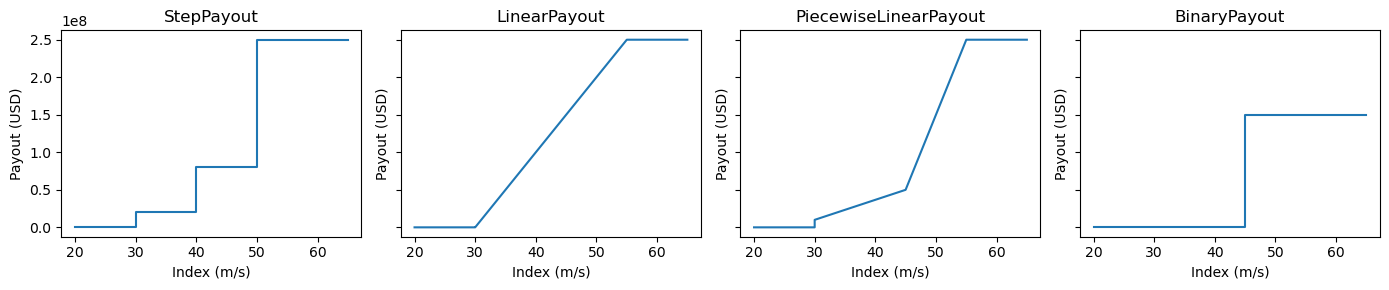

In [13]:
families = {
    "StepPayout": pm.StepPayout([30.0, 40.0, 50.0], [2e7, 8e7, 2.5e8]),
    "LinearPayout": pm.LinearPayout(attachment=30.0, exhaustion=55.0, limit=2.5e8),
    "PiecewiseLinearPayout": pm.PiecewiseLinearPayout(
        [30.0, 45.0, 55.0], [1e7, 5e7, 2.5e8]
    ),
    "BinaryPayout": pm.BinaryPayout(trigger=45.0, amount=1.5e8),
}
figure, axes = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
for axis, (name, payout) in zip(axes, families.items()):
    family_cover = pm.ParametricCover(
        index.definition, payout, unit_id=["site"], payout_unit="USD"
    )
    pm.plot_payout(family_cover, axis=axis, index_range=(20.0, 65.0))
    axis.set_title(name)
figure.tight_layout()

drought = pm.StepPayout([-1.0, -2.0], [5.0, 20.0], tail="lower")
print("A lower-tail step at -1 and -2:", drought.evaluate([0.0, -1.0, -1.5, -2.5]))

## 4. What a design computes

This section states the methods behind `calibrate` and `evaluate`, which the module's docstrings describe in full.

### 4.1 Outcomes: the event basis and the annual basis

A CLIMADA hazard is an event set: each event has a frequency per year, and years exist only if the catalogue carries them. A **basis** says what one **outcome** is, the thing a tail measure ranks. It is always stated; there is no default.

- **The event basis**, `EventBasis()`: one outcome per event $e$, with weight $f_e$, its frequency per year. $E[X] = \sum_e f_e X_e$ is an expected value per year, and $E[L]$ is the `Impact`'s `aai_agg` on the units. $1 - \beta$ is read as a frequency per year: $\mathrm{VaR}_\beta(X)$ is the smallest $x$ with $\sum_{X_e > x} f_e \le 1 - \beta$, CLIMADA's event exceedance curve at the return period $1 / (1 - \beta)$. Frequencies are not divided by their sum, so events with no loss and no index change nothing. It works for every hazard set.
- **The annual basis**: one outcome per simulated year $o$, with weight $1/N$. In a year, the uncovered loss sums each event's shortfall, $U_o = \sum_{e \in o} (L_e - \pi_e)^+$, so an over-payment in one event doesn't make up for a shortfall in another; the residual $R_o = L_o - \pi_o$ sums the year's losses and payouts. $\mathrm{CVaR}_{0.99}$ is then the mean of the worst 1 % of years. It takes a stated **route**:
  - `CatalogueYears`: a year label on each event, from the dates, the event names or an array. Every event the sample keeps must have the frequency $1/N$; otherwise `YearRouteError`.
  - `YearSets`: years drawn from the frequencies, each a Poisson number of events, with replacement and with your `numpy.random.Generator`. Any frequencies work. The sampled years carry sampling error: ask for at least 10,000.

Which route suits which hazard set is guidance, not code: catalogue years where the years are the data (STORM's 10,000 simulated years, read from the event names; an observed record, from the dates), year sets for ensembles whose members are not years of their own (`random_walk`, windstorm) and for every frequency-scaled set.

### 4.2 Objectives

With outcome weights $w_o$, losses $L_o$, payouts $\pi_o$ and the uncovered loss $U_o$:

- `MSE()`: $\sum_o w_o (L_o - \pi_o)^2$. Over-payment counts like under-payment.
- `ExpectedUncovered()`: $E[U] = \sum_o w_o U_o$. Over-payment is not rewarded.
- `WeightedCVaR(alpha, beta)`: $\alpha\,\mathrm{CVaR}_\beta(U) + (1 - \alpha)\,E[U]$, a mixture of the tail and the mean of the uncovered loss. $\alpha$ weights the tail term; $\beta$ is the tail level.
- `UserObjective(function, name=...)`: any function `function(loss, payout, weight)` of the outcome arrays (section 15).

### 4.3 Pricing, budget and limit

- `PurePremium()`: the premium is $E[\pi]$. `CostOfCapitalLoad(rate=r, q=q)`: $(1 - r)\,E[\pi] + r\,\mathrm{CVaR}_q(\pi)$, the expected payout plus a load for the capital held against the payout's tail.
- `Budget(ratio=κ)`: the premium is at most $\kappa\,E[L]$, on the design sample. `Budget(amount=B)`: at most $B$.
- `Limit(amount)` or `Limit.largest_loss()`: the most one event pays at one unit, a term of the cover.

### 4.4 Solvers and routes

For a payout that is linear in its amounts (the four families are), the payout of event $e$ is $\pi_e = B_e \theta$, with $\theta$ the free amounts. With the thresholds fixed, `ExpectedUncovered` and `WeightedCVaR` are **linear programs**. In the form of Rockafellar and Uryasev (2000), with a shortfall $u_e$ per event with a loss and auxiliaries $\zeta$ and $v_o$:

$$
\min_{\theta, u, \zeta, v}\; \alpha \Big( \zeta + \frac{1}{1 - \beta} \sum_o w_o v_o \Big) + (1 - \alpha) \sum_o w_o \sum_{e \in o} u_e
$$

subject to $u_e \ge L_e - B_e \theta$, $u_e \ge 0$, $v_o \ge \sum_{e \in o} u_e - \zeta$, $v_o \ge 0$, $\zeta \ge 0$, the budget $\sum_o w_o \sum_{e \in o} B_e \theta \le \kappa\,E[L]$ under the pure premium, and the amounts' own constraints: bounds, the limit, and monotone levels. `ExpectedUncovered` is the case $\alpha = 0$. Under a cost-of-capital load, the budget gets the same Rockafellar-Uryasev form for the payout's CVaR, so the problem stays linear. scipy's HiGHS solves it (`scipy.optimize.linprog`), with `"highs"` for one unit and `"highs-ipm"` for several by default.

`MSE` is a **quadratic program** in the amounts. scipy has no public QP solver, so it is solved with `scipy.optimize.minimize(method="SLSQP")` and its analytic gradient. Under a cost-of-capital load, cutting planes hold the premium within the budget, one round at a time. Both have stated limits (`CalibrationOptions.max_slsqp_amounts`, `max_cut_rounds`), and a limit reached raises `CalibrationLimitError`.

The **grid route** takes the rest, one design problem per unit: free thresholds, each on a stated grid, with the exact solve at every candidate; and payouts that are not linear in their amounts, or a `UserObjective`, on a grid over every free parameter, evaluated in numpy. The design keeps the objective at every candidate (`profile`).

After every solve, numpy recomputes the objective, the premium, the budget and every constraint from the returned amounts. A violation, or a solver status other than optimal, raises a `CalibrationError`. Nothing falls back to other amounts.

### 4.5 What a design can't tell

- **Unidentified amounts.** A step that no design outcome reaches changes nothing on the design sample, whatever its level. The design lists such amounts (`unidentified`) and sets them by a stated rule (`fill="lowest"` by default). An evaluation reports how much of its sample lands on them (`unidentified_share`). Section 12 shows it.
- **Non-unique optima.** On a linear program, other amounts can reach the same objective. `CalibrationOptions(ranges=True)` ranges every amount over the near-optimal set and decides `unique` (section 8).
- **Degenerate tails.** When $1 - \beta$ covers every outcome with a loss, the weighted CVaR has the same minimisers as $E[U]$; the design records it in `degenerate_tail`.

### 4.6 The calibration scope

- `scope="individual"`: one design problem per unit, with its own objective on its own loss and payout, its own budget and its own premium.
- `scope="joint"`: one design problem for one risk owner. Each unit keeps its own index and payout function and pays by its own terms, but the objective is on the owner's **total** per event, $L_e = \sum_j L_{e,j}$ and $\pi_e = \sum_j \pi_{e,j}$, under one budget on the total premium. Within an event, an over-payment at one unit can offset a shortfall at another.

These are two methods. What each optimises is stated here; nothing in the module says which one gives the better cover. Section 9 shows each on its own rows.

## 5. Jamaica: data from the CLIMADA Data API, units and indices

### 5.1 The data

The case is Jamaica, for tropical cyclones:

- **Exposures:** LitPop for Jamaica at 150 arcsec, asset values in USD (Eberenz et al., 2020).
- **Hazard:** the STORM set for Jamaica: 10,000 simulated years of tropical cyclones (Bloemendaal et al., 2020), as wind fields on 300 arcsec centroids. Section 12 adds the observed storms of 1980 to 2020, and section 13 the `random_walk` set of 1980 to 2020 with its rcp 4.5 futures.
- **Impact functions:** the regionally calibrated tropical cyclone functions of Eberenz et al. (2021). `ImpfSetTropCyclone.get_impf_id_regions_per_countries` gives Jamaica's region, the Caribbean and Mexico.

The Data API states each dataset's licence. The next cell prints them, with the versions this notebook read:

In [14]:
client = Client()
TC_STORM = "TC_JAM_0300as_STORM"
TC_PRESENT = "tropical_cyclone_10synth_tracks_150arcsec_JAM_1980_2020"
TC_RCP45 = [
    f"tropical_cyclone_10synth_tracks_150arcsec_rcp45_JAM_{year}"
    for year in (2040, 2060, 2080)
]
TC_OBSERVED = "tropical_cyclone_0synth_tracks_150arcsec_historical_JAM_1980_2020"
WS_LUX = "storm_europe_150arcsec_LUX"
DATASETS = [
    ("litpop", "LitPop_150arcsec_JAM"),
    ("litpop", "LitPop_150arcsec_LUX"),
    *[
        ("tropical_cyclone", name)
        for name in (TC_STORM, TC_PRESENT, *TC_RCP45, TC_OBSERVED)
    ],
    ("storm_europe", WS_LUX),
]
terms = []
for data_type, name in DATASETS:
    info = client.get_dataset_info(data_type=data_type, name=name)
    size = sum(file.file_size for file in info.files) / 1e6
    terms.append(
        {
            "name": name,
            "version": info.version,
            "MB": round(size, 1),
            "licence": info.license,
        }
    )
pd.DataFrame(terms)

,name,version,MB,licence
0,LitPop_150arcsec_JAM,v3,1.1,Attribution 4.0 International (CC-BY-4.0)
1,LitPop_150arcsec_LUX,v3,1.1,Attribution 4.0 International (CC-BY-4.0)
2,TC_JAM_0300as_STORM,v1.1,164.0,Attribution 4.0 International (CC-BY-4.0)
3,tropical_cyclone_10synth_tracks_150arcsec_JAM_1980_2020,v2.1,6.2,Attribution 4.0 International (CC-BY-4.0)
4,tropical_cyclone_10synth_tracks_150arcsec_rcp45_JAM_2040,v2.1,6.2,Attribution 4.0 International (CC-BY-4.0)
5,tropical_cyclone_10synth_tracks_150arcsec_rcp45_JAM_2060,v2.1,6.2,Attribution 4.0 International (CC-BY-4.0)
6,tropical_cyclone_10synth_tracks_150arcsec_rcp45_JAM_2080,v2.1,6.2,Attribution 4.0 International (CC-BY-4.0)
7,tropical_cyclone_0synth_tracks_150arcsec_historical_JAM_1980_2020,v2,0.5,Attribution 4.0 International (CC-BY-4.0)
8,storm_europe_150arcsec_LUX,v1.2,14.1,Attribution 4.0 International (CC-BY-4.0)


STORM's file holds every storm of its global set, 712,800 events; only those with wind at one of Jamaica's centroids can cause a loss or pay. The next cell keeps them, a subset that changes no number: an event without wind has no loss and an index of 0, and `OutcomeSample.from_impact` would leave it out anyway. The frequencies stay $1/10{,}000$ per event.

In [15]:
storm = client.get_hazard("tropical_cyclone", name=TC_STORM)
n_storm = storm.size
storm = storm.select(event_id=storm.event_id[storm.intensity.getnnz(axis=1) > 0])

jamaica = client.get_litpop("JAM")
impf_id, region, region_name = ImpfSetTropCyclone.get_impf_id_regions_per_countries(
    countries=["JAM"]
)
jamaica.gdf["impf_TC"] = impf_id[0]
tc_impfs = ImpfSetTropCyclone.from_calibrated_regional_ImpfSet()
impact = ImpactCalc(jamaica, tc_impfs, storm).impact(save_mat=True)

print(f"STORM: {storm.size} of {n_storm} events with wind over Jamaica, in m/s")
print(f"LitPop: {jamaica.gdf.shape[0]} points, {jamaica.value_unit}")
print(f"impact function {impf_id[0]}: {region_name[0]} ({region[0]})")

STORM: 4233 of 712800 events with wind over Jamaica, in m/s
LitPop: 542 points, USD
impact function 1: Caribbean and Mexico (NA1)


### 5.2 Insured units: a point, regions, the whole country

A unit is what gets one payout function. Three choices on the same exposures:

- **A point:** the exposure point of the largest value, as a single site. `InsuredUnits.from_column` leaves the points with no value in the column out of every unit, and logs how many.
- **Regions:** three bands of longitude, west, centre and east, from polygons (`InsuredUnits.from_geometries`). They are an illustration, not Jamaica's administrative parishes, whose boundaries are not on the Data API.
- **The whole country:** one unit of every point, `InsuredUnits.whole`.

Every unit's loss is `imp_mat` summed over its points, and its payout goes back to its points by their share of its value.

WARNING climada_petals: 541 of 542 exposure points are in no insured unit; their losses are left out


share of value per region: {'west': 0.13, 'centre': 0.273, 'east': 0.597}


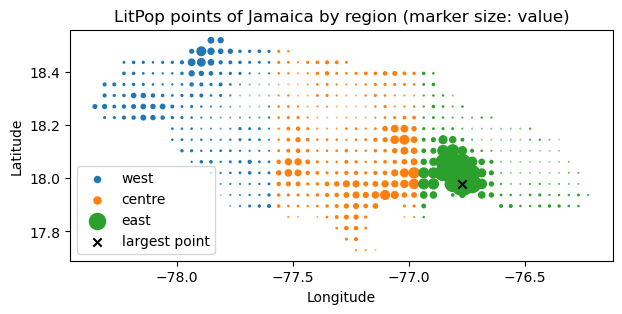

In [16]:
largest = int(np.argmax(jamaica.gdf["value"].to_numpy()))
jamaica.gdf["site"] = None
jamaica.gdf.loc[jamaica.gdf.index[largest], "site"] = "largest point"
point = pm.InsuredUnits.from_column(jamaica, "site")

BANDS = gpd.GeoDataFrame(
    {"region": ["west", "centre", "east"]},
    geometry=[
        box(-78.5, 17.6, -77.6, 18.6),
        box(-77.6, 17.6, -76.95, 18.6),
        box(-76.95, 17.6, -76.1, 18.6),
    ],
    crs="EPSG:4326",
)
regions = pm.InsuredUnits.from_geometries(jamaica, BANDS, id_column="region")
country = pm.InsuredUnits.whole(jamaica, unit_id="Jamaica")

shares = pd.Series(regions.unit_value / regions.unit_value.sum(), index=regions.unit_id)
print("share of value per region:", shares.round(3).to_dict())

figure, axis = plt.subplots(figsize=(7, 3))
for k, unit_id in enumerate(regions.unit_id):
    inside = regions.point_unit == k
    axis.scatter(
        regions.coords[inside, 1],
        regions.coords[inside, 0],
        s=regions.value[inside] / 2e7,
        label=unit_id,
    )
axis.scatter(
    *regions.coords[largest, ::-1], marker="x", color="k", label="largest point"
)
axis.set_xlabel("Longitude")
axis.set_ylabel("Latitude")
axis.set_title("LitPop points of Jamaica by region (marker size: value)")
axis.legend()
plt.show()

### 5.3 Index choices

The index is where basis risk comes from, so each choice is stated in the cover's `IndexDefinition` and in every table:

- **The wind at the point's centroid**, `index_stat="at_centroid"`, for a unit of one point.
- **A regional statistic:** the mean wind over a region's centroids, weighted by the value of its points (`index_stat="mean", weight="value"`), as `cat_bonds` uses `"mean"` or a percentile.
- **Readings at one place per region:** a user's table of index values, `ParametricIndex.from_table`. Here the table holds STORM's wind at one centroid per region, the one of the region's largest point: a stand-in for a network of wind stations, not real station data.
- **Cat-in-a-circle** needs the storms' tracks, which the Data API doesn't serve; section 2.5 built it on synthetic tracks, and it works the same on tracks from `TCTracks.from_ibtracs_netcdf`.

In [17]:
point_index = pm.ParametricIndex.from_hazard(storm, point)
region_index = pm.ParametricIndex.from_hazard(
    storm, regions, index_stat="mean", weight="value"
)
country_index = pm.ParametricIndex.from_hazard(
    storm, country, index_stat="mean", weight="value"
)

centroid = regions.centroids(storm)
readings = []
for k, unit_id in enumerate(regions.unit_id):
    inside = np.flatnonzero(regions.point_unit == k)
    top = inside[np.argmax(regions.value[inside])]
    wind = storm.intensity[:, centroid[top]].toarray().ravel()
    readings.append(
        pd.DataFrame({"event_id": storm.event_id, "unit_id": unit_id, "value": wind})
    )
readings = pd.concat(readings, ignore_index=True)
station_index = pm.ParametricIndex.from_table(
    readings,
    regions,
    definition=pm.IndexDefinition(
        "table", unit="m/s", source="wind at one centroid per region"
    ),
)
for name, built in [
    ("point", point_index),
    ("regions", region_index),
    ("country", country_index),
    ("station", station_index),
]:
    print(f"{name:8s}", built.definition)

point    IndexDefinition(kind='hazard', unit='m/s', tail='upper', index_stat='at_centroid', weight=None, source=None, parameters=mappingproxy({'haz_type': 'TC'}))
regions  IndexDefinition(kind='hazard', unit='m/s', tail='upper', index_stat='mean', weight='value', source=None, parameters=mappingproxy({'haz_type': 'TC'}))
country  IndexDefinition(kind='hazard', unit='m/s', tail='upper', index_stat='mean', weight='value', source=None, parameters=mappingproxy({'haz_type': 'TC'}))
station  IndexDefinition(kind='table', unit='m/s', tail='upper', index_stat=None, weight=None, source='wind at one centroid per region', parameters=None)


### 5.4 The annual basis on STORM

STORM's 10,000 years are its data, but its dates don't carry them: they span a single year. The event names carry them, `..._1000_YEARS_<k>.txt-<y>-<n>` for storm $n$ of year $y$ in the $k$-th thousand years, so year $1000\,k + y$ goes to `CatalogueYears.from_labels`. Every event has the frequency $1/10{,}000$, as catalogue years require.

On the event basis, the expected loss of a sample is the `Impact`'s `aai_agg`, which the next cell checks. On catalogue years over the whole sample it is the mean annual loss, which equals it when every event has the frequency $1/N$.

The split cuts contiguous years: years 0 to 6,999 design a cover, years 7,000 to 9,999 test it. Every unit choice gets its sample on the same years.

In [18]:
STORM_NAME = (
    r"STORM_DATA_IBTRACS_[A-Z]+_1000_YEARS_(?P<k>[0-9])\.txt-(?P<y>[0-9]+)-[0-9]+"
)
found = pm.labels_from_names(storm.event_name, STORM_NAME, ("k", "y"))
storm_year = 1000 * np.asarray(found["k"], dtype=int) + np.asarray(
    found["y"], dtype=int
)
storm_years = pm.CatalogueYears.from_labels(storm.event_id, storm_year, n_years=10_000)

samples = {
    name: pm.OutcomeSample.from_impact(built, impact, units=units_, basis=storm_years)
    for name, built, units_ in [
        ("point", point_index, point),
        ("regions", region_index, regions),
        ("country", country_index, country),
        ("station", station_index, regions),
    ]
}
sides = {name: pm.holdout(each, train_fraction=0.7) for name, each in samples.items()}
train, test = sides["regions"]
print(f"route {train.route}: {train.n_years} design years, {test.n_years} test years")

on_events = pm.OutcomeSample.from_impact(
    country_index, impact, units=country, basis=pm.EventBasis()
)
probe = pm.ParametricCover(
    country_index.definition,
    pm.BinaryPayout(50.0, 1e9),
    unit_id=country.unit_id,
    payout_unit="USD",
)
check = pm.evaluate(probe, on_events, split="out_of_sample")
print(
    "expected_loss / aai_agg on the event basis:",
    check["expected_loss"].iloc[-1] / impact.aai_agg,
)

INFO climada_petals: outcome sample: 908 of 4233 events have no loss and an index of 0 at every unit, and are left out


INFO climada_petals: outcome sample: 584 of 4233 events have no loss and an index of 0 at every unit, and are left out


route catalogue: 7000 design years, 3000 test years
expected_loss / aai_agg on the event basis: 0.9999999999999994


`index_diagnostics` reads, per unit, how far each index determines the loss on the whole sample. Section 11 returns to these numbers.

In [19]:
pd.concat(
    [pm.index_diagnostics(each).assign(index=name) for name, each in samples.items()]
)[
    [
        "index",
        "unit_id",
        "n_events",
        "spearman",
        "monotone_gap",
        "comonotone_index",
        "zero_index_loss_share",
    ]
].round(
    3
)

,index,unit_id,n_events,spearman,monotone_gap,comonotone_index,zero_index_loss_share
0,point,largest point,3325,0.978,0.000,True,0.0
0,regions,west,3723,0.970,0.077,False,0.0
1,regions,centre,3903,0.976,0.062,False,0.0
2,regions,east,3862,0.979,0.019,False,0.0
0,country,Jamaica,4233,0.963,0.107,False,0.0
0,station,west,3124,0.949,0.404,False,0.0
1,station,centre,3291,0.970,0.409,False,0.0
2,station,east,3337,0.985,0.305,False,0.0


## 6. Three objectives at one budget

One template for the three regions: a step payout on the regional mean wind, with breakpoints at 30, 38, 46, 54 and 62 m/s and free levels (`StepPayout.uniform(30, 70, 5)`), each level at most the region's largest event loss on the design years. Three designs, one per objective, each with one design problem per region, under the pure premium and the same budget: a premium of at most half the region's expected annual loss.

- `MSE()`: the squared annual residual;
- `ExpectedUncovered()`: the expected uncovered loss;
- `WeightedCVaR(alpha=0.9, beta=0.99)`: 90 % on the mean uncovered loss of the worst 1 % of years, 10 % on its mean.

The label of each template names its objective, so that the rows can be told apart.

In [20]:
def step_template(label, unit_id=regions.unit_id, definition=region_index.definition):
    """Return the step template of sections 6 to 10: five free levels, 30 to 70 m/s."""
    return pm.ParametricCover(
        definition,
        pm.StepPayout.uniform(attachment=30.0, exhaustion=70.0, n_steps=5),
        unit_id=unit_id,
        payout_unit="USD",
        limit=pm.Limit.largest_loss(),
        label=label,
    )


HALF = pm.Budget(ratio=0.5)
OBJECTIVES = {
    "MSE": pm.MSE(),
    "E[U]": pm.ExpectedUncovered(),
    "weighted CVaR": pm.WeightedCVaR(alpha=0.9, beta=0.99),
}
designs = {
    label: pm.calibrate(
        step_template(label), train, objective, scope="individual", budget=HALF
    )
    for label, objective in OBJECTIVES.items()
}
pd.concat([design.summary().assign(design=label) for label, design in designs.items()])[
    [
        "design",
        "problem_id",
        "route",
        "method",
        "budget_use",
        "n_unidentified",
        "unique",
        "degenerate_tail",
    ]
]

INFO climada_petals: design problem 'west': mse = 7.74006e+16, premium 7.85101e+07 (scipy-slsqp, slsqp, 0.00 s)


INFO climada_petals: design problem 'centre': mse = 3.63334e+17, premium 1.73017e+08 (scipy-slsqp, slsqp, 0.00 s)


INFO climada_petals: design problem 'east': mse = 1.87113e+18, premium 3.8567e+08 (scipy-slsqp, slsqp, 0.00 s)


INFO climada_petals: design problem 'west': expected_uncovered = 7.85101e+07, premium 7.85101e+07 (scipy-highs, highs, 0.01 s)


INFO climada_petals: design problem 'centre': expected_uncovered = 1.73017e+08, premium 1.73017e+08 (scipy-highs, highs, 0.01 s)


INFO climada_petals: design problem 'east': expected_uncovered = 3.8567e+08, premium 3.8567e+08 (scipy-highs, highs, 0.01 s)


INFO climada_petals: design problem 'west': weighted_cvar = 1.53121e+09, premium 7.85101e+07 (scipy-highs, highs, 0.01 s)


INFO climada_petals: design problem 'centre': weighted_cvar = 3.31679e+09, premium 1.73017e+08 (scipy-highs, highs, 0.01 s)


INFO climada_petals: design problem 'east': weighted_cvar = 7.59868e+09, premium 3.8567e+08 (scipy-highs, highs, 0.01 s)


,design,problem_id,route,method,budget_use,n_unidentified,unique,degenerate_tail
0,MSE,west,qp,slsqp,1.0,0,True,None
1,MSE,centre,qp,slsqp,1.0,0,True,None
2,MSE,east,qp,slsqp,1.0,0,True,None
0,E[U],west,lp,highs,1.0,0,None,None
1,E[U],centre,lp,highs,1.0,0,None,None
2,E[U],east,lp,highs,1.0,0,None,None
0,weighted CVaR,west,lp,highs,1.0,0,None,None
1,weighted CVaR,centre,lp,highs,1.0,0,None,None
2,weighted CVaR,east,lp,highs,1.0,0,None,None


The summary holds how each design problem was solved: the MSE on the QP route, the other two on the LP route, every budget used in full, and no unidentified level. `unique` is decided on the QP route; on the LP route it needs `ranges=True` (section 8).

`compare` evaluates several covers on one sample, here the 3,000 test years. The table ranks nothing. Its metrics, per row:

- `expected_loss`, `premium`, `expected_payout`: per year;
- `coverage_ratio`: $E[\min(\pi, L)] / E[L]$;
- `tail_coverage_b0_99`: the share of the loss covered in the worst 1 % of years by loss;
- `cvar_uncovered_b0_99`: the mean uncovered loss of the worst 1 % of years by uncovered loss;
- `payout_frequency`: the probability of a year with a payout;
- `false_negative_rate_l0`: the probability of no payout in a year with a loss.

In [21]:
COLUMNS = [
    "expected_loss",
    "premium",
    "expected_payout",
    "coverage_ratio",
    "tail_coverage_b0_99",
    "cvar_uncovered_b0_99",
    "payout_frequency",
    "false_negative_rate_l0",
]
MONEY = ["expected_loss", "premium", "expected_payout", "cvar_uncovered_b0_99"]
table = pm.compare(list(designs.values()), test, split="out_of_sample")
view(table, COLUMNS, money=MONEY)

,cover_label,level,unit_id,expected_loss [M USD],premium [M USD],expected_payout [M USD],coverage_ratio,tail_coverage_b0_99,cvar_uncovered_b0_99 [M USD],payout_frequency,false_negative_rate_l0
0,MSE,unit,west,169.471,78.510,91.088,0.537,0.766,1630.756,0.048,0.790
1,MSE,unit,centre,370.064,173.017,190.899,0.516,0.706,3536.927,0.146,0.390
2,MSE,unit,east,799.260,385.670,388.056,0.486,0.764,8273.518,0.147,0.376
3,MSE,total,None,1338.795,637.198,670.044,0.500,0.741,12242.778,0.157,0.395
4,E[U],unit,west,169.471,78.510,90.168,0.532,0.580,2044.443,0.048,0.790
5,E[U],unit,centre,370.064,173.017,168.896,0.456,0.593,5977.086,0.146,0.390
6,E[U],unit,east,799.260,385.670,388.486,0.486,0.372,14234.453,0.147,0.376
7,E[U],total,None,1338.795,637.198,647.550,0.484,0.456,19768.975,0.157,0.395
8,weighted CVaR,unit,west,169.471,78.510,91.087,0.537,0.782,1632.625,0.048,0.790
9,weighted CVaR,unit,centre,370.064,173.017,189.851,0.513,0.709,3570.036,0.049,0.795


In [22]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units west, centre, east
Payout threshold: 0


What the table shows, on this setup only (STORM's test years 7,000 to 9,999, three regions, the value-weighted mean wind, this step template, the pure premium and a budget of half the expected loss): the three designs spend the same premium. The weighted-CVaR design pays in fewer of the test years (about 6 % of them, against about 16 % for the other two) and covers the largest share of the loss of the worst 1 % of years, the MSE design close to it; the E[U] design covers the smallest share of those years' loss. Their coverage ratios are close, and the E[U] design's is not the highest, although E[U] is what it minimised on the design years: 7,000 years still leave sampling error between the two sides. This is the mechanism of the objectives on this setup: the weighted CVaR puts the budget on the top steps, which the worst years reach; the E[U] design returned here, one of many optimal ones (section 8), pays from lower steps on. It is not a statement about other hazards, units, budgets or pricings.

The three payout functions of the east region, and each test event's payout against its loss under the weighted-CVaR design:

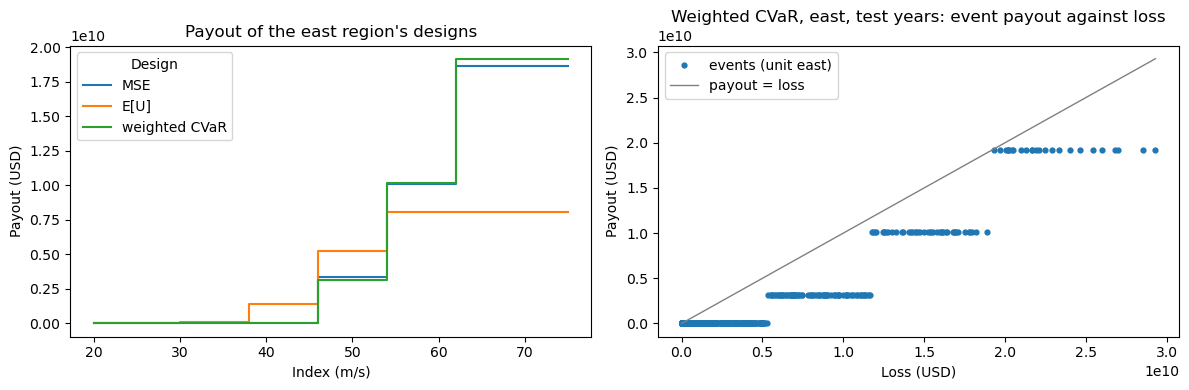

In [23]:
figure, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
for design in designs.values():
    pm.plot_payout(design.cover, "east", axis=left, index_range=(20.0, 75.0))
left.legend(left.get_lines(), list(designs), title="Design")
left.set_title("Payout of the east region's designs")
pm.plot_payout_vs_loss(designs["weighted CVaR"], test, unit_id="east", axis=right)
right.set_title("Weighted CVaR, east, test years: event payout against loss")
figure.tight_layout()

### 6.1 A loaded premium

Under a cost-of-capital load, the premium of a payout $\pi$ is $(1 - r)\,E[\pi] + r\,\mathrm{CVaR}_q(\pi)$. The budget then bounds the loaded premium, so the design can pay less on average. On the QP route of the MSE, cutting planes hold the loaded premium within the budget, one round at a time; the summary states the rounds. On the LP route the load stays linear (section 4.4).

In [24]:
LOAD = pm.CostOfCapitalLoad(rate=0.1, q=0.99)
loaded = pm.calibrate(
    step_template("MSE, loaded"),
    train,
    pm.MSE(),
    scope="individual",
    pricing=LOAD,
    budget=HALF,
)
print(loaded.summary()[["problem_id", "route", "rounds", "budget_use"]])
table = pm.evaluate(loaded, test, split="out_of_sample")
view(
    table,
    [
        "premium",
        "premium_repriced",
        "expected_payout",
        "coverage_ratio",
        "tail_coverage_b0_99",
    ],
    money=["premium", "premium_repriced", "expected_payout"],
)

INFO climada_petals: design problem 'west': mse = 3.21499e+17, premium 7.85101e+07 (scipy-slsqp, slsqp, 0.00 s)


INFO climada_petals: design problem 'centre': mse = 1.47826e+18, premium 1.73017e+08 (scipy-slsqp, slsqp, 0.00 s)


INFO climada_petals: design problem 'east': mse = 7.72791e+18, premium 3.8567e+08 (scipy-slsqp, slsqp, 0.00 s)


  problem_id route  rounds  budget_use
0       west    qp       4         1.0
1     centre    qp       5         1.0
2       east    qp       4         1.0


,cover_label,level,unit_id,premium [M USD],premium_repriced [M USD],expected_payout [M USD],coverage_ratio,tail_coverage_b0_99
0,"MSE, loaded",unit,west,78.510,75.559,24.439,0.144,0.111
1,"MSE, loaded",unit,centre,173.017,166.584,53.737,0.145,0.119
2,"MSE, loaded",unit,east,385.670,354.782,117.350,0.147,0.110
3,"MSE, loaded",total,None,637.198,596.926,195.526,0.146,0.116


In [25]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: cost_of_capital(q=0.99, rate=0.1); premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units west, centre, east
Payout threshold: 0


`premium` is the design premium, the contract's price; `premium_repriced` is the same pricing on the test years.

## 7. The budget frontier

`calibrate_frontier` calibrates one template at several budgets and returns the designs as one table: what another unit of premium buys. It is a measurement with no best point, and its objective values and premiums are on the design sample. So the out-of-sample numbers come from calibrating at each budget and evaluating each design on the test years, as the next cell does; `calibrate_frontier` gives the same designs in one call, which the cell checks.

In [26]:
RATIOS = (0.25, 0.5, 0.75, 1.0)
wcvar = OBJECTIVES["weighted CVaR"]
frontier = pm.calibrate_frontier(
    step_template("frontier"),
    train,
    wcvar,
    budgets=[pm.Budget(ratio=ratio) for ratio in RATIOS],
    scope="individual",
)
by_budget = {
    ratio: pm.calibrate(
        step_template(f"weighted CVaR, budget {ratio}"),
        train,
        wcvar,
        scope="individual",
        budget=pm.Budget(ratio=ratio),
    )
    for ratio in RATIOS
}
same = all(
    np.isclose(
        frontier.loc[
            (frontier["budget_ratio"] == ratio) & (frontier["problem_id"] == unit),
            f"{unit}:levels[{k}]",
        ].item(),
        design.cover.payout[unit].levels[k],
    )
    for ratio, design in by_budget.items()
    for unit in regions.unit_id
    for k in range(5)
)
print("calibrate_frontier gives the same designs:", same)

table = pm.compare(list(by_budget.values()), test, split="out_of_sample")
totals = table[table["level"] == "total"]
view(totals, COLUMNS, money=MONEY)

INFO climada_petals: design problem 'west': weighted_cvar = 2.42205e+09, premium 3.92551e+07 (scipy-highs, highs, 0.01 s)


INFO climada_petals: design problem 'centre': weighted_cvar = 5.18461e+09, premium 8.65087e+07 (scipy-highs, highs, 0.02 s)


INFO climada_petals: design problem 'east': weighted_cvar = 1.18487e+10, premium 1.92835e+08 (scipy-highs, highs, 0.02 s)


INFO climada_petals: design problem 'west': weighted_cvar = 1.53121e+09, premium 7.85101e+07 (scipy-highs, highs, 0.01 s)


INFO climada_petals: design problem 'centre': weighted_cvar = 3.31679e+09, premium 1.73017e+08 (scipy-highs, highs, 0.01 s)


INFO climada_petals: design problem 'east': weighted_cvar = 7.59868e+09, premium 3.8567e+08 (scipy-highs, highs, 0.02 s)


... (17 outputs left out)

INFO climada_petals: design problem 'east': weighted_cvar = 2.43525e+09, premium 7.7134e+08 (scipy-highs, highs, 0.01 s)


calibrate_frontier gives the same designs:

 True


,cover_label,level,unit_id,expected_loss [M USD],premium [M USD],expected_payout [M USD],coverage_ratio,tail_coverage_b0_99,cvar_uncovered_b0_99 [M USD],payout_frequency,false_negative_rate_l0
0,"weighted CVaR, budget 0.25",total,None,1338.795,318.599,346.705,0.259,0.533,19182.606,0.057,0.781
1,"weighted CVaR, budget 0.5",total,None,1338.795,637.198,669.332,0.500,0.755,12246.373,0.062,0.762
2,"weighted CVaR, budget 0.75",total,None,1338.795,955.796,993.643,0.734,0.920,6876.100,0.109,0.581
3,"weighted CVaR, budget 1.0",total,None,1338.795,1274.395,1324.093,0.915,0.970,3104.807,0.109,0.581


Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: the owner's total over the units
Payout threshold: 0


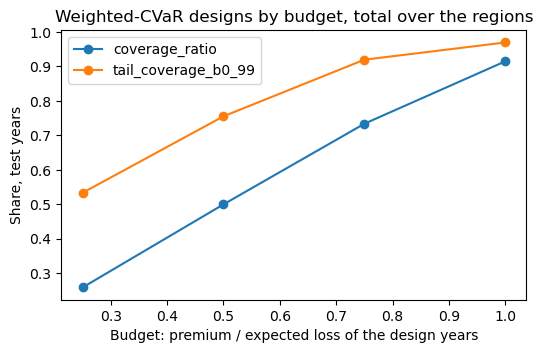

In [27]:
print(pm.setup_text(totals))

figure, axis = plt.subplots(figsize=(6, 3.5))
for column in ("coverage_ratio", "tail_coverage_b0_99"):
    axis.plot(RATIOS, totals[column], marker="o", label=column)
axis.set_xlabel("Budget: premium / expected loss of the design years")
axis.set_ylabel("Share, test years")
axis.set_title("Weighted-CVaR designs by budget, total over the regions")
axis.legend()
plt.show()

## 8. A free attachment, and the ranges of a design

**A free threshold** takes the grid route: `LinearPayout(Free(25, 45, grid=11), 70, Free())` searches the attachment on 11 values from 25 to 45 m/s and solves the limit exactly at each, one design problem per region. The design keeps the search in `profile`: the objective at every candidate on the design sample, which candidates tie with the best, and which was chosen. Ties go to the first candidate. Here many attachments tie: under this budget, with E[U], any attachment at which the whole budget can be spent without paying more than the loss reaches the same objective.

The profile is the search's view, on the design years. The design's numbers come from the test years.

INFO climada_petals: design problem 'west': 11 grid candidates of ['attachment'], 11 feasible, 6 tied with the chosen one


INFO climada_petals: design problem 'centre': 11 grid candidates of ['attachment'], 11 feasible, 6 tied with the chosen one


INFO climada_petals: design problem 'east': 11 grid candidates of ['attachment'], 11 feasible, 6 tied with the chosen one


INFO climada_petals: design problem 'west': expected_uncovered = 7.85101e+07, premium 7.85101e+07 (scipy-highs, highs, 0.04 s)


INFO climada_petals: design problem 'centre': expected_uncovered = 1.73017e+08, premium 1.73017e+08 (scipy-highs, highs, 0.04 s)


INFO climada_petals: design problem 'east': expected_uncovered = 3.8567e+08, premium 3.8567e+08 (scipy-highs, highs, 0.04 s)


  problem_id route  n_candidates  ties
0       west    lp            11     6
1     centre    lp            11     6
2       east    lp            11     6


,cover_label,level,unit_id,premium [M USD],coverage_ratio,tail_coverage_b0_99,payout_frequency
0,"linear, free attachment",unit,west,78.510,0.493,0.393,0.115
1,"linear, free attachment",unit,centre,173.017,0.492,0.394,0.120
2,"linear, free attachment",unit,east,385.670,0.499,0.381,0.123
3,"linear, free attachment",total,None,637.198,0.497,0.389,0.144


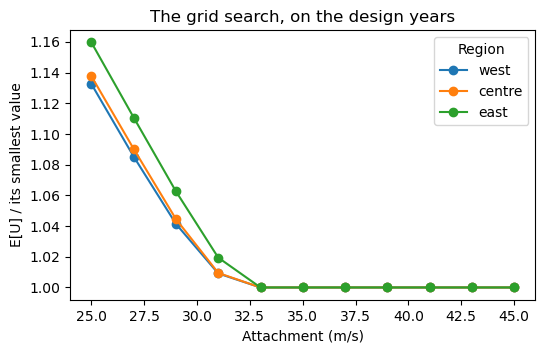

In [28]:
linear = pm.ParametricCover(
    region_index.definition,
    pm.LinearPayout(pm.Free(25.0, 45.0, grid=11), 70.0, pm.Free()),
    unit_id=regions.unit_id,
    payout_unit="USD",
    limit=pm.Limit.largest_loss(),
    label="linear, free attachment",
)
searched = pm.calibrate(
    linear, train, pm.ExpectedUncovered(), scope="individual", budget=HALF
)
profile = searched.profile
print(searched.summary()[["problem_id", "route", "n_candidates", "ties"]])

figure, axis = plt.subplots(figsize=(6, 3.5))
for unit_id, rows in profile.groupby("problem_id", sort=False):
    axis.plot(
        rows["attachment"],
        rows["objective_value"] / rows["objective_value"].min(),
        marker="o",
        label=unit_id,
    )
axis.set_xlabel("Attachment (m/s)")
axis.set_ylabel("E[U] / its smallest value")
axis.set_title("The grid search, on the design years")
axis.legend(title="Region")

table = pm.evaluate(searched, test, split="out_of_sample")
view(
    table,
    ["premium", "coverage_ratio", "tail_coverage_b0_99", "payout_frequency"],
    money=["premium"],
)

In [29]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units west, centre, east
Payout threshold: 0


**Ranges.** A linear program returns one optimal vertex, which may be one member of a set of optimal designs. `CalibrationOptions(ranges=True)` ranges every amount over the near-optimal set: four more linear programs per amount, each as large as the design problem. `unique` is then decided, and `ranges` holds each level's range. On the E[U] design of section 6, the levels are not unique: their ranges are wide, because many splits of the budget across the steps reach the same E[U].

The cost grows with the problem: on a joint design (section 9) each ranging LP is as large as the whole joint problem. On the joint weighted-CVaR design of section 9.3 the ranges took about 12 s on the laptop this notebook ran on, against about 1 s for the individual design below. So use it on individual designs, or state its cost.

In [30]:
started = time.perf_counter()
ranged = pm.calibrate(
    step_template("E[U], ranged"),
    train,
    pm.ExpectedUncovered(),
    scope="individual",
    budget=HALF,
    options=pm.CalibrationOptions(ranges=True),
)
print(f"unique: {ranged.unique}; ranges took {time.perf_counter() - started:.1f} s")
pd.DataFrame(ranged.ranges["east"], index=["low [M USD]", "high [M USD]"]).T.div(
    1e6
).round(1)

INFO climada_petals: design problem 'west': expected_uncovered = 7.85101e+07, premium 7.85101e+07 (scipy-highs, highs, 0.33 s)


INFO climada_petals: design problem 'centre': expected_uncovered = 1.73017e+08, premium 1.73017e+08 (scipy-highs, highs, 0.37 s)


INFO climada_petals: design problem 'east': expected_uncovered = 3.8567e+08, premium 3.8567e+08 (scipy-highs, highs, 0.37 s)


unique: False; ranges took 1.1 s


,low [M USD],high [M USD]
levels[0],0.0,73.2
levels[1],0.0,1384.5
levels[2],787.0,5215.2
levels[3],4165.5,11726.6
levels[4],8065.7,19298.5


## 9. The calibration scope

The scope says which units share a design problem (section 4.6). Each scope gets its own rows here, with what it optimises and the budget it uses. The tables are not set side by side: this tutorial makes no comparison of the two scopes.

### 9.1 Individual calibration

Each region is its own design problem: E[U] of the region's own uncovered loss, under the region's own budget, a pure premium of at most half its expected loss on the design years. The `"unit"` rows are each region's own cover, and the `"total"` row the owner's total, whose premium is the sum of the regions' premiums.

In [31]:
individual = designs["E[U]"]
table = pm.evaluate(individual, test, split="out_of_sample")
view(table, COLUMNS, money=MONEY)

,cover_label,level,unit_id,expected_loss [M USD],premium [M USD],expected_payout [M USD],coverage_ratio,tail_coverage_b0_99,cvar_uncovered_b0_99 [M USD],payout_frequency,false_negative_rate_l0
0,E[U],unit,west,169.471,78.510,90.168,0.532,0.580,2044.443,0.048,0.790
1,E[U],unit,centre,370.064,173.017,168.896,0.456,0.593,5977.086,0.146,0.390
2,E[U],unit,east,799.260,385.670,388.486,0.486,0.372,14234.453,0.147,0.376
3,E[U],total,None,1338.795,637.198,647.550,0.484,0.456,19768.975,0.157,0.395


In [32]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units west, centre, east
Payout threshold: 0


### 9.2 Joint calibration

One design problem for the owner of all three regions: E[U] of the owner's uncovered loss, the expected annual sum of the shortfalls $(L_e - \pi_e)^+$ of each event, with $L_e$ and $\pi_e$ summed over the regions, under one budget: a total pure premium of at most half the total expected loss on the design years. Each region keeps its own index and step payout, and pays by its own terms. Thresholds are fixed in a joint design.

A joint design has one `"total"` row. Its objective sees only each event's total payout, so other splits of the payouts across the regions are often optimal too, and the regions' levels are the one split the solver returned. Per-unit rows exist only under a stated allocation: `MetricOptions(allocation="value")` gives each region the share of the total payout that its value has of the total value. They are an accounting statement, with no premium.

In [33]:
joint = pm.calibrate(
    step_template("E[U], joint"),
    train,
    pm.ExpectedUncovered(),
    scope="joint",
    budget=HALF,
)
print(joint.summary()[["problem_id", "route", "method", "budget_use"]])
table = pm.evaluate(
    joint, test, split="out_of_sample", options=pm.MetricOptions(allocation="value")
)
view(table, COLUMNS, money=MONEY)

INFO climada_petals: design problem 'joint': expected_uncovered = 6.37198e+08, premium 6.37198e+08 (scipy-highs, highs-ipm, 0.01 s)


  problem_id route     method  budget_use
0      joint    lp  highs-ipm         1.0


,cover_label,level,unit_id,expected_loss [M USD],premium [M USD],expected_payout [M USD],coverage_ratio,tail_coverage_b0_99,cvar_uncovered_b0_99 [M USD],payout_frequency,false_negative_rate_l0
0,"E[U], joint",total,None,1338.795,637.198,647.191,0.483,0.733,13269.774,0.05,0.809
1,"E[U], joint",unit_by_value,west,169.471,NaN,84.306,0.443,0.633,2936.706,0.05,0.784
2,"E[U], joint",unit_by_value,centre,370.064,NaN,176.596,0.473,0.694,4667.014,0.05,0.792
3,"E[U], joint",unit_by_value,east,799.260,NaN,386.289,0.481,0.691,8590.333,0.05,0.789


In [34]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: joint calibration
Rows: the owner's total over the units; a joint design's total payout allocated by value (no premium); units west, centre, east
Payout threshold: 0


### 9.3 The combination: a tail objective on the owner's total

The weighted CVaR in the joint scope: $0.9\,\mathrm{CVaR}_{0.99}(U) + 0.1\,E[U]$ of the owner's total uncovered loss per year, under one budget of half the total expected loss, pure premium. It is a tail objective on what the owner bears over all three regions.

In [35]:
combination = pm.calibrate(
    step_template("weighted CVaR, joint"), train, wcvar, scope="joint", budget=HALF
)
table = pm.evaluate(combination, test, split="out_of_sample")
view(table, COLUMNS, money=MONEY)

INFO climada_petals: design problem 'joint': weighted_cvar = 1.12429e+10, premium 6.37198e+08 (scipy-highs, highs-ipm, 0.09 s)


,cover_label,level,unit_id,expected_loss [M USD],premium [M USD],expected_payout [M USD],coverage_ratio,tail_coverage_b0_99,cvar_uncovered_b0_99 [M USD],payout_frequency,false_negative_rate_l0
0,"weighted CVaR, joint",total,None,1338.795,637.198,677.121,0.506,0.765,11985.579,0.057,0.781


In [36]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: joint calibration
Rows: the owner's total over the units
Payout threshold: 0


## 10. Out-of-sample evaluation and CLIMADA objects

### 10.1 What `evaluate` refuses

A design remembers the sample it was cut from (its **source token**) and the events and years of its design side. An out-of-sample evaluation on a sample that shares any of them raises `LeakageError`: here, the whole STORM sample, whose first 7,000 years designed the cover.

In [37]:
try:
    pm.evaluate(combination, samples["regions"], split="out_of_sample")
except pm.LeakageError as error:
    print("LeakageError:", error)

LeakageError: 2944 events are in both samples, e.g. [144747, 144782, 144842, 144891, 144909]


### 10.2 One unit of a sample

`OutcomeSample.unit` keeps one unit of a sample, with its source token, so a design on one unit of the design side is checked against the other side too. The other points are in no unit, which the module logs.

In [38]:
east_train, east_test = train.unit("east"), test.unit("east")
east = pm.calibrate(
    step_template("weighted CVaR, east only", unit_id=["east"]),
    east_train,
    wcvar,
    scope="individual",
    budget=HALF,
)
print("same source as the whole sample:", east_test.source == samples["regions"].source)
table = pm.evaluate(east, east_test, split="out_of_sample")
view(table, ["premium", "coverage_ratio", "tail_coverage_b0_99"], money=["premium"])

WARNING climada_petals: 403 of 542 exposure points are in no insured unit; their losses are left out


WARNING climada_petals: 403 of 542 exposure points are in no insured unit; their losses are left out


INFO climada_petals: design problem 'east': weighted_cvar = 7.59868e+09, premium 3.8567e+08 (scipy-highs, highs, 0.01 s)


same source as the whole sample: True


,cover_label,level,unit_id,premium [M USD],coverage_ratio,tail_coverage_b0_99
0,"weighted CVaR, east only",unit,east,385.67,0.486,0.784
1,"weighted CVaR, east only",total,None,385.67,0.486,0.784


In [39]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units east
Payout threshold: 0


### 10.3 Exceedance curves

The table's return-period columns (`loss_rp<T>`, `payout_rp<T>`, `uncovered_rp<T>`, `net_loss_rp<T>`) are annual: the value a year exceeds with probability $1/T$, on the test years. `plot_exceedance` draws them. The net loss is the loss minus the payout plus the premium, what the owner bears in a year.

Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: joint calibration
Rows: the owner's total over the units
Payout threshold: 0

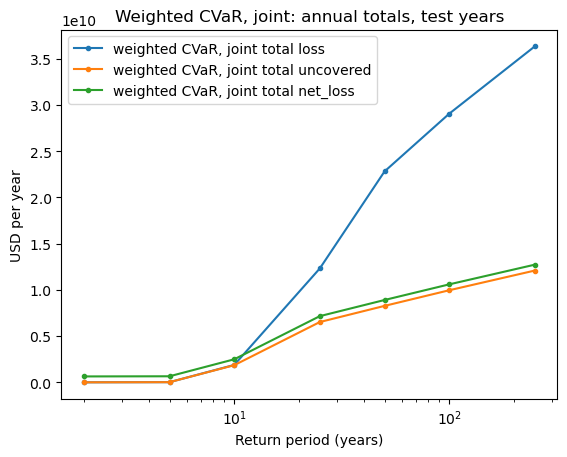

In [40]:
table = pm.evaluate(combination, test, split="out_of_sample")
axis = pm.plot_exceedance(table, quantities=("loss", "uncovered", "net_loss"))
axis.set_ylabel("USD per year")
axis.set_title("Weighted CVaR, joint: annual totals, test years")
print(pm.setup_text(table))

### 10.4 Payouts as an `Impact`

`payout_impact` returns the payouts as a CLIMADA `Impact`, on the exposure points of the loss, and `uncovered_impact` the uncovered losses; a region's payout goes to its points by value share. CLIMADA's tools work on them: `calc_freq_curve`, `local_exceedance_impact`, `write_hdf5`.

Their `aai_agg` uses the events' frequencies. On the event basis, and on catalogue years over a whole sample, it is the table's `expected_payout`. On a side of a catalogue split it is not: the test side's events keep the frequency $1/10{,}000$ while the side holds 3,000 years, so `aai_agg` is $3{,}000/10{,}000$ of `expected_payout`. Section 12 draws the curves of a payout `Impact` on a whole sample.

In [41]:
paid = pm.payout_impact(combination, test)
print(type(paid).__name__, paid.unit, paid.imp_mat.shape, "(events, points)")
print("aai_agg / expected_payout:", paid.aai_agg / table["expected_payout"].iloc[0])

Impact USD (1289, 542) (events, points)
aai_agg / expected_payout: 0.3


### 10.5 Writing a cover down

A cover holds terms and nothing else, so it can be written down and read back. `definition_hash` identifies its terms; it is the `cover_hash` column of every table, and it doesn't change with the label.

In [42]:
with tempfile.TemporaryDirectory() as folder:
    path = Path(folder) / "combination.json"
    combination.cover.write_json(path)
    read = pm.ParametricCover.from_json(path)
print("read back equal:", read == combination.cover)
print("hash:", read.definition_hash)
print("payout of the west region:", read.payout["west"])

read back equal: True
hash: sha256:9a620158183b69ceeb88a24ccf6b52c83ae095eb42fd6724ebfd5a2bc54f2c1f
payout of the west region: StepPayout(breakpoints=(30.0, 38.0, 46.0, 54.0, 62.0), levels=(0.0, 0.0, 0.0, 2134467982.2662838, 5005912332.422504), tail='upper', monotone=True)


## 11. Basis risk

A cover pays on its index; the owner bears the loss. Basis risk is what the index doesn't tell about the loss, and on CLIMADA's objects it comes from a stated source. **The structural sources come first**, where the index and the loss are different things:

- **An index that is not the footprint at the assets:** cat-in-a-circle from the tracks (section 2.5); readings at a few places, as a network of stations gives them (`from_table`, section 5.3); an index from another hazard set or a coarser resolution than the loss's, through `ParametricIndex.from_hazard` and `matched_to(impact, on="event_name")`.
- **A unit of several points**, with a statistic over its centroids (`"mean"`, `"max"` or a percentile): the footprint varies within the unit.

Each is recorded in the cover's `IndexDefinition`, and so in every table's `index_definition`. Impact-function draws come second (section 11.2).

### 11.1 The degenerate case, and a measurement

Where no structural source is present, with one exposure point, the wind at its own centroid as the index, and one impact function, CLIMADA's loss is a function of the index: a step payout with enough steps can follow it as closely as the steps allow, and the metrics then show almost no basis risk. That is a property of the setup, not of the cover. `index_diagnostics` detects it, and `calibrate` and `evaluate` log a warning and set `comonotone_index`, as for the point of section 5:

In [43]:
point_train, point_test = sides["point"]
pm.calibrate(
    step_template(
        "E[U], point", unit_id=point.unit_id, definition=point_index.definition
    ),
    point_train,
    pm.ExpectedUncovered(),
    scope="individual",
    budget=HALF,
).summary()[["problem_id", "comonotone_index"]]

WARNING climada_petals: calibrate: at 1 of 1 units, e.g. ['largest point'], the index determines the loss almost one-to-one (the loss is a non-decreasing function of the index within 1e-06 of its largest value, or the frequency-weighted Spearman correlation of index and loss is at least 0.99, oriented by the index's tail), so a cover can replicate the loss and basis risk reads close to zero. Basis risk needs a stated source: an index from another hazard set or resolution, a statistic over a group of points, a track-based trigger, a table of readings, or impact-function draws. The comonotone_index column marks these units


INFO climada_petals: design problem 'largest point': expected_uncovered = 4.55984e+07, premium 4.55984e+07 (scipy-highs, highs, 0.01 s)


,problem_id,comonotone_index
0,largest point,True


A measurement shows what that means. For the point, the regions and the readings at one place per region (the station table of section 5.3), all on the whole of STORM's design and test years, the next cell designs E[U] step covers from 26 to 80 m/s with 5, 20 and 80 steps, with a budget of the whole expected loss (`Budget(ratio=1.0)`, pure premium), and evaluates each on the test years. `uncovered_share` is $E[U] / E[L]$ of the total. A share that keeps falling as steps are added is what no basis risk looks like.

The warning of the point design repeats for each of its designs; the cell keeps the module's log to errors.

In [44]:
rows = []
with log_level("ERROR", name_prefix="climada_petals"):
    for name in ("point", "regions", "station"):
        design_side, test_side = sides[name]
        for n_steps in (5, 20, 80):
            template_k = pm.ParametricCover(
                design_side.index.definition,
                pm.StepPayout.uniform(
                    attachment=26.0, exhaustion=80.0, n_steps=n_steps
                ),
                unit_id=design_side.unit_id,
                payout_unit="USD",
                limit=pm.Limit.largest_loss(),
                label=f"{name}, {n_steps} steps",
            )
            fitted = pm.calibrate(
                template_k,
                design_side,
                pm.ExpectedUncovered(),
                scope="individual",
                budget=pm.Budget(ratio=1.0),
            )
            evaluated = pm.evaluate(fitted, test_side, split="out_of_sample")
            rows.append(evaluated[evaluated["level"] == "total"])
by_steps = pd.concat(rows, ignore_index=True)
by_steps["uncovered_share"] = by_steps["expected_uncovered"] / by_steps["expected_loss"]
view(
    by_steps,
    [
        "uncovered_share",
        "false_negative_rate_l0",
        "false_positive_rate_l0",
        "comonotone_index",
    ],
)

,cover_label,level,unit_id,uncovered_share,false_negative_rate_l0,false_positive_rate_l0,comonotone_index
0,"point, 5 steps",total,None,0.139,0.050,0.0,True
1,"point, 20 steps",total,None,0.036,0.050,0.0,True
2,"point, 80 steps",total,None,0.010,0.050,0.0,True
3,"regions, 5 steps",total,None,0.079,0.203,0.0,False
4,"regions, 20 steps",total,None,0.024,0.203,0.0,False
5,"regions, 80 steps",total,None,0.010,0.203,0.0,False
6,"station, 5 steps",total,None,0.119,0.213,0.0,False
7,"station, 20 steps",total,None,0.061,0.213,0.0,False
8,"station, 80 steps",total,None,0.056,0.213,0.0,False


In [45]:
print(pm.setup_text(by_steps))

Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: at_centroid, in m/s; haz_type=TC; hazard: mean, value-weighted, in m/s; haz_type=TC; table (wind at one centroid per region): in m/s
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: the owner's total over the units
Payout threshold: 0


On this setup (STORM's test years, E[U] at a budget of the whole expected loss, steps from 26 to 80 m/s): the uncovered share of the point falls towards zero as steps are added, as the degenerate case predicts. The regions' mean wind behaves much the same, although `index_diagnostics` doesn't flag it: on STORM's 300 arcsec centroids, a region's value-weighted mean wind determines most of its loss. The readings at one place per region level off. The false-negative rate at a loss of 0 doesn't move with the steps: it is set by the attachment, 26 m/s, since a year with a loss but no index value above it gets no payout, whatever the steps.

So the size of a unit doesn't settle basis risk, and a flag is a measurement with a threshold (0.99 on the Spearman correlation, by default), not a guarantee.

### 11.2 Impact-function draws come second

`impact_function_draws` stretches every impact function of a set above its threshold by one factor per draw, uniform on a stated range: uncertainty about the functions, common to every event and point of a draw. `OutcomeSample.from_impact_draws` takes one `Impact` per draw; each event then has one row per draw, with its frequency divided by the number of draws. A design calibrated on the draws sees a wider range of losses.

**Their limit.** Every drawn function keeps its threshold, so an event has a loss in a draw exactly where it has one without the draws, and the payout depends on the index only. So where the index is the hazard at the unit, the false-negative and false-positive rates at a loss of 0 are the same with and without the draws, as the table below shows. Basis risk in *which* events pay needs a structural source.

In [46]:
draws = pm.impact_function_draws(
    tc_impfs, n_draws=20, scale=(0.8, 1.25), rng=np.random.default_rng(320)
)
draw_impacts = [
    ImpactCalc(jamaica, drawn, storm).impact(save_mat=True) for drawn in draws
]
with_draws = pm.OutcomeSample.from_impact_draws(
    region_index, draw_impacts, units=regions, basis=storm_years
)
draws_train, draws_test = pm.holdout(with_draws, train_fraction=0.7)
print(
    f"{with_draws.n_events} events x {with_draws.n_draws} draws = {with_draws.n_rows} rows"
)

drawn_design = pm.calibrate(
    step_template("weighted CVaR, on draws"),
    draws_train,
    wcvar,
    scope="individual",
    budget=HALF,
)
table = pd.concat(
    [
        pm.evaluate(designs["weighted CVaR"], test, split="out_of_sample").assign(
            losses="one impact function set"
        ),
        pm.evaluate(drawn_design, draws_test, split="out_of_sample").assign(
            losses="20 draws"
        ),
    ],
    ignore_index=True,
)
totals = table[table["level"] == "total"]
view(
    totals,
    [
        "coverage_ratio",
        "tail_coverage_b0_99",
        "false_negative_rate_l0",
        "false_positive_rate_l0",
    ],
    keys=("cover_label", "losses", "level"),
)

4233 events x 20 draws = 84660 rows


INFO climada_petals: design problem 'west': weighted_cvar = 1.9564e+09, premium 7.23897e+07 (scipy-highs, highs, 1.28 s)


INFO climada_petals: design problem 'centre': weighted_cvar = 4.21724e+09, premium 1.59552e+08 (scipy-highs, highs, 1.71 s)


INFO climada_petals: design problem 'east': weighted_cvar = 9.69927e+09, premium 3.5562e+08 (scipy-highs, highs, 1.82 s)


,cover_label,losses,level,coverage_ratio,tail_coverage_b0_99,false_negative_rate_l0,false_positive_rate_l0
0,weighted CVaR,one impact function set,total,0.500,0.755,0.762,0.0
1,"weighted CVaR, on draws",20 draws,total,0.496,0.662,0.762,0.0


In [47]:
print(pm.setup_text(totals))

Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: the owner's total over the units
Payout threshold: 0


Both rows are on the test years 7,000 to 9,999: the first with the losses of the regional impact functions, the second with the losses of the 20 draws, each scaling the curves above their thresholds by a factor between 0.8 and 1.25.

## 12. A short record: 41 observed years, evaluated on STORM

A short record leaves the upper amounts of a cover unidentified: a step that no event of the record reaches changes nothing on it, whatever its level. In CLIMADA this is ordinary. The observed storms of 1980 to 2020 for Jamaica, read with `CatalogueYears.from_dates`, hold few events with wind, and none whose country-wide mean wind reaches the top step of a template from 20 to 70 m/s.

The design below is calibrated on the 41 observed years, for the whole country as one unit, with E[U] at a budget of half the expected loss. It lists its unidentified amounts, which the fill rule set to the level below (`fill="lowest"`).

In [48]:
observed = client.get_hazard("tropical_cyclone", name=TC_OBSERVED)
observed_index = pm.ParametricIndex.from_hazard(
    observed, country, index_stat="mean", weight="value"
)
observed_impact = ImpactCalc(jamaica, tc_impfs, observed).impact(save_mat=True)
record = pm.OutcomeSample.from_impact(
    observed_index,
    observed_impact,
    units=country,
    basis=pm.CatalogueYears.from_dates(observed),
)
print(f"{record.n_events} events with wind or a loss in {record.n_years} years")
print("largest index of the record (m/s):", round(float(record.index_values.max()), 1))

short = pm.calibrate(
    pm.ParametricCover(
        observed_index.definition,
        pm.StepPayout.uniform(attachment=20.0, exhaustion=70.0, n_steps=5),
        unit_id=country.unit_id,
        payout_unit="USD",
        limit=pm.Limit.largest_loss(),
        label="E[U], 41 observed years",
    ),
    record,
    pm.ExpectedUncovered(),
    scope="individual",
    budget=HALF,
)
print("unidentified:", dict(short.unidentified))

INFO climada_petals: outcome sample: 3877 of 3890 events have no loss and an index of 0 at every unit, and are left out


13 events with wind or a loss in 41 years
largest index of the record (m/s): 54.4
INFO climada_petals: design problem 'Jamaica': expected_uncovered = 6.32236e+08, premium 6.32236e+08 (scipy-highs, highs, 0.00 s)


unidentified: {'Jamaica': ('levels[4]',)}


STORM's 10,000 years share no event with the observed set, so they are out of sample by construction. The cover's index is rebuilt on STORM from its definition (`ParametricIndex.from_definition`). The two sets' year labels overlap (STORM's run from 0 to 9,999, so they include 1980 to 2020), so a check on ids and years alone would refuse them; the module compares the samples' source tokens instead, sees two event sets, and accepts the evaluation.

`unidentified_share` is the probability of a year with an event on a filled amount. On the design sample it is 0 by construction; on STORM it is not.

In [49]:
on_storm = pm.OutcomeSample.from_impact(
    pm.ParametricIndex.from_definition(short.cover.index, storm, country),
    impact,
    units=country,
    basis=storm_years,
)
table = pm.evaluate(short, on_storm, split="out_of_sample")
view(
    table[table["level"] == "total"],
    [
        "expected_loss",
        "premium",
        "expected_payout",
        "coverage_ratio",
        "unidentified_share",
    ],
    money=["expected_loss", "premium", "expected_payout"],
)

,cover_label,level,unit_id,expected_loss [M USD],premium [M USD],expected_payout [M USD],coverage_ratio,unidentified_share
0,"E[U], 41 observed years",total,None,1293.715,632.236,410.859,0.318,0.009


In [50]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 10000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units Jamaica
Payout threshold: 0


The design's premium was priced on the 41 years, and it stays the contract's price; on STORM's years the same cover's expected payout differs from it.

**Payout and uncovered losses as an `Impact`, on a whole sample.** On catalogue years over a whole sample, every event has the frequency $1/N$, so the `aai_agg` of the payout `Impact` is the table's `expected_payout`. Passing `impact=` keeps the loss `Impact`'s events, names and dates. `calc_freq_curve` then gives CLIMADA's **event** exceedance curves: the return period of one event's payout, loss or uncovered loss, not of a year's total, which the tables give.

aai_agg / expected_payout: 1.0000000000000002


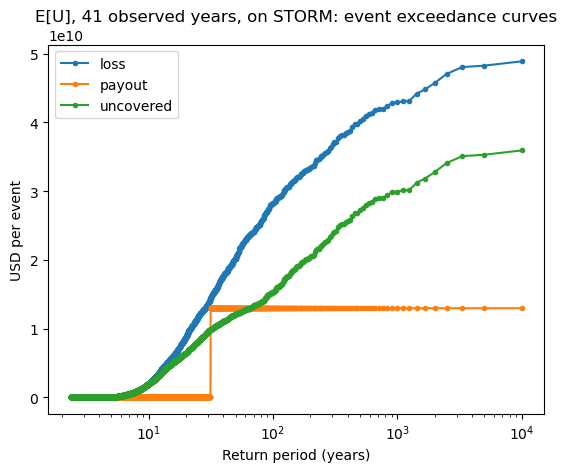

In [51]:
paid = pm.payout_impact(short, on_storm, impact=impact)
uncovered = pm.uncovered_impact(short, on_storm, impact=impact)
print("aai_agg / expected_payout:", paid.aai_agg / table["expected_payout"].iloc[-1])
axis = pm.plot_exceedance({"loss": impact, "payout": paid, "uncovered": uncovered})
axis.set_ylabel("USD per event")
axis.set_title("E[U], 41 observed years, on STORM: event exceedance curves")
plt.show()

## 13. Climate scenarios

In CLIMADA a scenario is another hazard set, and possibly other exposures. A cover holds no events and no frequencies, so it pays on any of them: `ParametricIndex.from_definition` rebuilds its index there. `ScenarioSet` maps labels to scenarios, builds their samples (`ScenarioSet.from_hazards`), and splits them together; `evaluate_scenarios` evaluates one cover on every scenario, and `calibrate_per_scenario` designs one per scenario. All samples of a set are on one basis and route.

### 13.1 Windows of a pathway

One horizon of one model can be noisy, so the scenario here is a **window**: the Data API's `random_walk` sets for Jamaica under rcp 4.5 at 2040, 2060 and 2080, as one scenario, an equal-weight mixture of the three. The present is the `random_walk` set of 1980 to 2020.

`random_walk` sets hold each observed storm of 1980 to 2020 with ten perturbed members. A member is another version of its parent storm, not a year of its own, so the route is year sets: 40,000 years sampled from the frequencies per set, at least 10,000 on each side of the split. Each member's block is its **parent storm**, read from the name (`<sid>_gen<m>`), so that a split keeps a storm's members together. The future sets hold the same parent storms with other footprints; `ScenarioSet.holdout` puts each parent on the same side in every set.

`from_hazards` computes each scenario's index on that scenario's units unless `index_units=` gives the units at inception, which keeps a value-weighted index on the contract's weights. Here the exposures are the same in every scenario, so the two choices agree.

In [52]:
present = client.get_hazard("tropical_cyclone", name=TC_PRESENT)
futures = [client.get_hazard("tropical_cyclone", name=name) for name in TC_RCP45]


def parents(hazard):
    """Return each event's parent storm: its name without the suffix _gen<m>."""
    return pm.labels_from_names(hazard.event_name, pm.ENSEMBLE_PARENT)["block"]


scenario_rng = np.random.default_rng(45)


def year_sets(hazard):
    """Return 40,000 years sampled from the hazard's frequencies, by parent storm."""
    return pm.YearSets.from_frequencies(
        hazard, n_years=40_000, rng=scenario_rng, block=parents(hazard)
    )


RCP45 = "rcp45, 2040 to 2080"
scenarios = pm.ScenarioSet.from_hazards(
    {"present": present, RCP45: futures},
    definition=region_index.definition,
    units=regions,
    impact_funcs=tc_impfs,
    basis=year_sets,
)
scenario_train, scenario_test = scenarios.holdout(rng=scenario_rng)
with_wind = present.intensity.getnnz(axis=1) > 0
test_parents = scenario_test.sample("present").parents
print(
    "parent storms with wind over Jamaica:",
    len(set(np.asarray(parents(present))[with_wind])),
)
print(
    "on the test side:",
    len(
        {
            test_parents[e]
            for e in scenario_test.sample("present").event_id
            if e in test_parents
        }
    ),
)
scenario_test.summary()

INFO climada_petals: outcome sample: 43401 of 43560 events have no loss and an index of 0 at every unit, and are left out


INFO climada_petals: outcome sample: 43401 of 43560 events have no loss and an index of 0 at every unit, and are left out


INFO climada_petals: outcome sample: 43401 of 43560 events have no loss and an index of 0 at every unit, and are left out


INFO climada_petals: outcome sample: 43401 of 43560 events have no loss and an index of 0 at every unit, and are left out


parent storms with wind over Jamaica: 36
on the test side: 9


,scenario,members,basis,route,n_years,n_events,n_draws,split,fold
0,present,1,annual,yearsets,12075,48,1,test,0
1,"rcp45, 2040 to 2080",3,annual,yearsets,36225,144,1,test,0


The file holds 36 parent storms that bring wind to Jamaica, and the test side 9 of them. A few storms carry most of the loss, so the two sides' expected losses differ widely (the training sides' are printed below, the test sides' are in the tables), and every number of this section carries this sampling error of the event set itself, which more sampled years don't reduce.

One weighted-CVaR design per scenario, on its training side, each with one design problem per region and a budget of half the region's expected loss in that scenario. `designs_table` puts the designs' terms side by side: the levels of the east region, in million USD.

In [53]:
per_scenario = pm.calibrate_per_scenario(
    step_template("weighted CVaR, per scenario"),
    scenario_train,
    wcvar,
    scope="individual",
    budget=HALF,
)
terms = pm.designs_table(per_scenario)
levels = [f"east:levels[{k}]" for k in range(5)]
east_terms = terms.loc[
    terms["problem_id"] == "east", ["scenario", "budget_use", *levels]
]
east_terms[levels] = (east_terms[levels] / 1e6).round(1)
design_loss = terms.groupby("scenario", sort=False)["expected_loss"].sum() / 1e6
print("expected loss of the training sides [M USD]:", design_loss.round(1).to_dict())
east_terms.set_index("scenario")

INFO climada_petals: design problem 'west': weighted_cvar = 1.50365e+09, premium 4.82119e+07 (scipy-highs, highs, 0.02 s)


INFO climada_petals: design problem 'centre': weighted_cvar = 3.90175e+09, premium 1.44416e+08 (scipy-highs, highs, 0.02 s)


INFO climada_petals: design problem 'east': weighted_cvar = 9.42715e+09, premium 3.4941e+08 (scipy-highs, highs, 0.02 s)


INFO climada_petals: design problem 'west': weighted_cvar = 1.45744e+09, premium 5.67485e+07 (scipy-highs, highs, 0.12 s)


INFO climada_petals: design problem 'centre': weighted_cvar = 4.31818e+09, premium 1.67459e+08 (scipy-highs, highs, 0.15 s)


INFO climada_petals: design problem 'east': weighted_cvar = 1.01806e+10, premium 4.06902e+08 (scipy-highs, highs, 0.17 s)


expected loss of the training sides [M USD]: {'present': 1084.1, 'rcp45, 2040 to 2080': 1262.2}


,budget_use,east:levels[0],east:levels[1],east:levels[2],east:levels[3],east:levels[4]
scenario,,,,,,
present,1.0,0.0,0.0,1290.2,8279.7,14274.4
"rcp45, 2040 to 2080",1.0,0.0,0.0,0.0,7478.9,15257.8


The present design, a fixed contract, on both scenarios' test sides: its premium stays the design premium, `premium_repriced` prices its payouts in each scenario.

In [54]:
SCENARIO_COLUMNS = [
    "n_years",
    "expected_loss",
    "premium",
    "premium_repriced",
    "coverage_ratio",
    "tail_coverage_b0_99",
]
SCENARIO_MONEY = ["expected_loss", "premium", "premium_repriced"]
table = pm.evaluate_scenarios(
    per_scenario["present"], scenario_test, split="out_of_sample"
)
view(
    table[table["level"] == "total"],
    SCENARIO_COLUMNS,
    money=SCENARIO_MONEY,
    keys=("cover_label", "scenario"),
)

,cover_label,scenario,n_years,expected_loss [M USD],premium [M USD],premium_repriced [M USD],coverage_ratio,tail_coverage_b0_99
0,"weighted CVaR, per scenario",present,12075,413.373,542.037,134.144,0.325,0.458
1,"weighted CVaR, per scenario","rcp45, 2040 to 2080",36225,482.420,542.037,144.459,0.299,0.396


In [55]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 12075, 36225 sampled years (route yearsets)
Scenario: present; rcp45, 2040 to 2080
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units west, centre, east
Payout threshold: 0


Each scenario's own design, on its own scenario's test side:

In [56]:
own = pd.concat(
    [
        pm.evaluate_scenarios(
            design,
            pm.ScenarioSet({label: list(scenario_test.members[label])}),
            split="out_of_sample",
        )
        for label, design in per_scenario.items()
    ],
    ignore_index=True,
)
view(
    own[own["level"] == "total"],
    SCENARIO_COLUMNS,
    money=SCENARIO_MONEY,
    keys=("cover_label", "scenario"),
)

,cover_label,scenario,n_years,expected_loss [M USD],premium [M USD],premium_repriced [M USD],coverage_ratio,tail_coverage_b0_99
0,"weighted CVaR, per scenario",present,12075,413.373,542.037,134.144,0.325,0.458
1,"weighted CVaR, per scenario","rcp45, 2040 to 2080",36225,482.420,631.109,94.549,0.196,0.316


In [57]:
print(pm.setup_text(own))

Split: out of sample, fold 0
Basis: annual basis on 12075, 36225 sampled years (route yearsets)
Scenario: present; rcp45, 2040 to 2080
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units west, centre, east
Payout threshold: 0


The whole future set holds the present design's parent storms, the ones it was calibrated on, so `evaluate_scenarios` on it raises `LeakageError` (section 10.1): the test sides cut by `ScenarioSet.holdout` are the out-of-sample samples.

### 13.2 A frequency-scaled set

`TropCyclone.apply_climate_scenario_knu` scales the frequencies of a set by storm category, after Knutson et al. (2020) and Jewson (2021). The Data API's files hold neither each event's category nor its basin, and without them the method returns the set unchanged. So the next cell sets **stand-ins**: each event's category is the Saffir-Simpson category of its largest wind over Jamaica's centroids, a lower bound of its track's category, and every basin is the North Atlantic, where the storms that reach Jamaica form. The scaled set then changes the frequencies of the storms with wind over Jamaica, by category.

It keeps the events, so the present set and the scaled set have one source token. `ScenarioSet.holdout` cuts both with the same blocks, and the present design is evaluated on the scaled set's test side, not on the whole scaled set, which holds the events it was calibrated on. Its frequencies are no longer $1/N$, so the route is year sets again.

In [58]:
KN_TO_MS = 1852.0 / 3600.0


def with_categories(hazard):
    """Return the set as a TropCyclone with stand-ins for each event's category and basin."""
    wind = hazard.intensity.max(axis=1).toarray().ravel()
    bounds = np.asarray(SAFFIR_SIM_CAT[:-1], dtype=float) * KN_TO_MS
    return TropCyclone(
        category=np.searchsorted(bounds, wind, side="right") - 1,
        basin=["NA"] * hazard.size,
        units=hazard.units,
        centroids=hazard.centroids,
        event_id=hazard.event_id,
        event_name=hazard.event_name,
        frequency=hazard.frequency,
        frequency_unit=hazard.frequency_unit,
        date=hazard.date,
        orig=hazard.orig,
        intensity=hazard.intensity,
        fraction=hazard.fraction,
    )


baseline = with_categories(present)
scaled = baseline.apply_climate_scenario_knu(
    percentile="50", scenario="4.5", target_year=2060
)
ratio = scaled.frequency[with_wind] / baseline.frequency[with_wind]
print("frequency ratios of the storms with wind:", np.unique(ratio.round(3)))

KNU = "rcp45, 2060, frequency-scaled"
scaled_set = pm.ScenarioSet.from_hazards(
    {"present": baseline, KNU: scaled},
    definition=region_index.definition,
    units=regions,
    impact_funcs=tc_impfs,
    basis=year_sets,
)
scaled_train, scaled_test = scaled_set.holdout(rng=scenario_rng)
present_design = pm.calibrate(
    step_template("weighted CVaR, present"),
    scaled_train.sample("present"),
    wcvar,
    scope="individual",
    budget=HALF,
)
table = pm.evaluate_scenarios(present_design, scaled_test, split="out_of_sample")
view(
    table[table["level"] == "total"],
    SCENARIO_COLUMNS,
    money=SCENARIO_MONEY,
    keys=("cover_label", "scenario"),
)

frequency ratios of the storms with wind: [0.881 1.073]


INFO climada_petals: outcome sample: 43401 of 43560 events have no loss and an index of 0 at every unit, and are left out


INFO climada_petals: outcome sample: 43401 of 43560 events have no loss and an index of 0 at every unit, and are left out


INFO climada_petals: design problem 'west': weighted_cvar = 1.26514e+09, premium 4.53128e+07 (scipy-highs, highs, 0.03 s)


INFO climada_petals: design problem 'centre': weighted_cvar = 3.61763e+09, premium 1.43921e+08 (scipy-highs, highs, 0.02 s)


INFO climada_petals: design problem 'east': weighted_cvar = 8.36801e+09, premium 3.32625e+08 (scipy-highs, highs, 0.02 s)


,cover_label,scenario,n_years,expected_loss [M USD],premium [M USD],premium_repriced [M USD],coverage_ratio,tail_coverage_b0_99
0,"weighted CVaR, present",present,12075,516.785,521.859,186.739,0.361,0.487
1,"weighted CVaR, present","rcp45, 2060, frequency-scaled",11999,531.904,521.859,189.353,0.356,0.497


In [59]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 12075, 11999 sampled years (route yearsets)
Scenario: present; rcp45, 2060, frequency-scaled
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units west, centre, east
Payout threshold: 0


## 14. A second hazard: windstorm in Luxembourg

Nothing above is specific to tropical cyclones. The same steps on European windstorm in Luxembourg:

- **Hazard:** the Data API's windstorm set for Luxembourg (WISC), 142 historical storms of 1940 to 2013, each with 30 members; an event's id is 100 × its storm + its member.
- **Exposures:** LitPop for Luxembourg, in two units, west and east of 6.1° E.
- **Impact function:** Schwierz et al. (2010), CLIMADA's function for European winter storms.

The file's event names are numbers, which CLIMADA casts to text with a warning that the cell keeps out.

In [60]:
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore", message="Not all values are of type", category=UserWarning
    )
    winter = client.get_hazard("storm_europe", name=WS_LUX)
luxembourg = client.get_litpop("LUX")
luxembourg.gdf["impf_WS"] = 1
ws_impact = ImpactCalc(
    luxembourg, ImpactFuncSet([ImpfStormEurope.from_schwierz()]), winter
).impact(save_mat=True)

HALVES = gpd.GeoDataFrame(
    {"part": ["west", "east"]},
    geometry=[box(5.5, 49.3, 6.1, 50.3), box(6.1, 49.3, 6.7, 50.3)],
    crs="EPSG:4326",
)
halves = pm.InsuredUnits.from_geometries(luxembourg, HALVES, id_column="part")
ws_index = pm.ParametricIndex.from_hazard(
    winter, halves, index_stat="mean", weight="value"
)
print(
    f"{winter.size} events, {winter.frequency.sum():.2f} events per year, wind in {winter.units}"
)

4260 events, 1.95 events per year, wind in m/s


**The route.** The dates span 74 winter seasons, while the frequency of each event, $1/(73 \times 30)$, implies 73 years of 30 members. Catalogue years from the dates don't fit, and the module says so rather than collapsing the years:

In [61]:
try:
    pm.OutcomeSample.from_impact(
        ws_index,
        ws_impact,
        units=halves,
        basis=pm.CatalogueYears.from_dates(winter, season_start_month=7),
    )
except pm.YearRouteError as error:
    print("YearRouteError:", error)

YearRouteError: 4260 of the sample's 4260 events have frequency x N between 0.03379 and 0.03379, not 1, with N = 74 (the dates' seasons from month 7 from 1940). On catalogue years every event the sample keeps has frequency 1 / N. A frequency-scaled or perturbed set takes YearSets or the event basis; dates that don't carry the years take from_event_names or from_labels


Year sets fit: 40,000 years sampled from the frequencies, with each storm's 30 members as one block, so that a split keeps them together. Then the three objectives of section 6, on a step template from 25 to 40 m/s in three steps, each with one design problem per part, pure premium, budget half the expected loss:

In [62]:
ws_rng = np.random.default_rng(14)
ws_sample = pm.OutcomeSample.from_impact(
    ws_index,
    ws_impact,
    units=halves,
    basis=pm.YearSets.from_frequencies(
        winter, n_years=40_000, rng=ws_rng, block=np.asarray(winter.event_id) // 100
    ),
)
ws_train, ws_test = pm.holdout(ws_sample, train_fraction=0.7, rng=ws_rng)
ws_designs = [
    pm.calibrate(
        pm.ParametricCover(
            ws_index.definition,
            pm.StepPayout.uniform(attachment=25.0, exhaustion=40.0, n_steps=3),
            unit_id=halves.unit_id,
            payout_unit="USD",
            limit=pm.Limit.largest_loss(),
            label=label,
        ),
        ws_train,
        objective,
        scope="individual",
        budget=HALF,
    )
    for label, objective in OBJECTIVES.items()
]
table = pm.compare(ws_designs, ws_test, split="out_of_sample")
view(table, COLUMNS, money=MONEY)

INFO climada_petals: design problem 'west': mse = 8.37162e+11, premium 242137 (scipy-slsqp, slsqp, 0.00 s)


INFO climada_petals: design problem 'east': mse = 1.18587e+12, premium 280783 (scipy-slsqp, slsqp, 0.00 s)


INFO climada_petals: design problem 'west': expected_uncovered = 252699, premium 242137 (scipy-highs, highs, 0.01 s)


INFO climada_petals: design problem 'east': expected_uncovered = 292134, premium 280783 (scipy-highs, highs, 0.01 s)


INFO climada_petals: design problem 'west': weighted_cvar = 6.53691e+06, premium 242137 (scipy-highs, highs, 0.08 s)


INFO climada_petals: design problem 'east': weighted_cvar = 7.83055e+06, premium 280783 (scipy-highs, highs, 0.08 s)


,cover_label,level,unit_id,expected_loss [M USD],premium [M USD],expected_payout [M USD],coverage_ratio,tail_coverage_b0_99,cvar_uncovered_b0_99 [M USD],payout_frequency,false_negative_rate_l0
0,MSE,unit,west,0.601,0.242,0.318,0.464,0.667,7.226,0.269,0.595
1,MSE,unit,east,0.608,0.281,0.342,0.512,0.480,7.303,0.094,0.850
2,MSE,total,None,1.209,0.523,0.660,0.508,0.655,13.560,0.269,0.603
3,E[U],unit,west,0.601,0.242,0.284,0.439,0.633,7.893,0.269,0.595
4,E[U],unit,east,0.608,0.281,0.299,0.463,0.405,8.240,0.237,0.621
5,E[U],total,None,1.209,0.523,0.583,0.464,0.574,15.221,0.270,0.601
6,weighted CVaR,unit,west,0.601,0.242,0.327,0.456,0.663,7.307,0.095,0.857
7,weighted CVaR,unit,east,0.608,0.281,0.345,0.520,0.486,7.227,0.094,0.850
8,weighted CVaR,total,None,1.209,0.523,0.672,0.511,0.672,13.560,0.096,0.858


In [63]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 12113 sampled years (route yearsets)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=WS
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units west, east
Payout threshold: 0


## 15. Extending the module: a payout and an objective of your own

### 15.1 A payout family

A payout family is a frozen dataclass that implements `PayoutFunction`: a `kind`, a `tail` and `evaluate`. A family that is linear in its amounts implements `LinearInAmounts` instead, `amount_names` and `basis`, and the calibration's exact routes take it. `register_payout` lets a cover's document name it, so the cover round-trips through JSON.

The family below pays $\ell\,((s - a) / (e - a))^2$ between an attachment $a$ and an exhaustion $e$, and $\ell$ beyond: a convex ramp, linear in its one amount, the limit $\ell$.

In [64]:
@pm.register_payout
@dataclass(frozen=True)
class ConvexRamp(pm.LinearInAmounts):
    """Payout ``limit * ((s - a) / (e - a)) ** 2`` from the attachment to the exhaustion."""

    kind: ClassVar[str] = "convex_ramp"

    attachment: Any
    exhaustion: Any
    limit: Any
    tail: str = "upper"

    def amount_names(self):
        """Return the names of the amounts: the limit."""
        return ("limit",)

    def basis(self, index):
        """Return the squared share of the ramp at each index value, as one column."""
        share = (self.severity(index) - self.attachment) / (
            self.exhaustion - self.attachment
        )
        return sp.csr_matrix(np.clip(share, 0.0, 1.0)[:, None] ** 2)


ramp = pm.ParametricCover(
    region_index.definition,
    ConvexRamp(30.0, 70.0, pm.Free()),
    unit_id=regions.unit_id,
    payout_unit="USD",
    limit=pm.Limit.largest_loss(),
    label="convex ramp, weighted CVaR",
)
ramp_design = pm.calibrate(ramp, train, wcvar, scope="individual", budget=HALF)
print("route:", ramp_design.summary()["route"].unique())
print(
    "read back equal:",
    pm.ParametricCover.from_dict(ramp_design.cover.to_dict()) == ramp_design.cover,
)
table = pm.evaluate(ramp_design, test, split="out_of_sample")
view(
    table,
    ["premium", "coverage_ratio", "tail_coverage_b0_99", "payout_frequency"],
    money=["premium"],
)

INFO climada_petals: design problem 'west': weighted_cvar = 1.88363e+09, premium 7.85101e+07 (scipy-highs, highs, 0.01 s)


INFO climada_petals: design problem 'centre': weighted_cvar = 3.98592e+09, premium 1.73017e+08 (scipy-highs, highs, 0.01 s)


INFO climada_petals: design problem 'east': weighted_cvar = 9.51173e+09, premium 3.8567e+08 (scipy-highs, highs, 0.01 s)


route: ['lp']
read back equal: True


,cover_label,level,unit_id,premium [M USD],coverage_ratio,tail_coverage_b0_99,payout_frequency
0,"convex ramp, weighted CVaR",unit,west,78.510,0.504,0.575,0.139
1,"convex ramp, weighted CVaR",unit,centre,173.017,0.506,0.572,0.146
2,"convex ramp, weighted CVaR",unit,east,385.670,0.501,0.554,0.147
3,"convex ramp, weighted CVaR",total,None,637.198,0.502,0.559,0.169


In [65]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units west, centre, east
Payout threshold: 0


A family that is not linear in its amounts implements `evaluate` alone; the calibration then searches every free parameter on its stated grid, in numpy.

### 15.2 An objective

A `UserObjective` is any function of the outcome arrays, the annual losses $L_o$, payouts $\pi_o$ and weights $w_o$, that returns a float. It is evaluated, not compiled into a program, so the calibration takes the grid route: every free parameter needs finite bounds and a grid. The objective below is the expected squared annual shortfall, $\sum_o w_o ((L_o - \pi_o)^+)^2$, which weighs large shortfalls more than small ones. The payout is binary, its trigger on 5 values from 30 to 50 m/s and its amount on 11 values up to the region's largest event loss on the design years.

In [66]:
def squared_shortfall(loss, payout, weight):
    """Return the expected squared annual shortfall."""
    return float(weight @ np.maximum(loss - payout, 0.0) ** 2)


largest_loss = dict(zip(regions.unit_id, train.loss.max(axis=0).toarray().ravel()))
binary = pm.ParametricCover(
    region_index.definition,
    {
        unit_id: pm.BinaryPayout(
            pm.Free(30.0, 50.0, grid=5), pm.Free(0.0, largest_loss[unit_id], grid=11)
        )
        for unit_id in regions.unit_id
    },
    unit_id=regions.unit_id,
    payout_unit="USD",
    label="binary, squared shortfall",
)
shortfall_design = pm.calibrate(
    binary,
    train,
    pm.UserObjective(squared_shortfall, name="squared_shortfall"),
    scope="individual",
    budget=HALF,
)
print(shortfall_design.summary()[["problem_id", "route", "n_candidates", "ties"]])
table = pm.evaluate(shortfall_design, test, split="out_of_sample")
view(
    table,
    ["premium", "coverage_ratio", "tail_coverage_b0_99", "payout_frequency"],
    money=["premium"],
)

INFO climada_petals: design problem 'west': 55 grid candidates of ['trigger', 'amount'], 12 feasible, 0 tied with the chosen one


INFO climada_petals: design problem 'centre': 55 grid candidates of ['trigger', 'amount'], 13 feasible, 0 tied with the chosen one


INFO climada_petals: design problem 'east': 55 grid candidates of ['trigger', 'amount'], 12 feasible, 0 tied with the chosen one


INFO climada_petals: design problem 'west': squared_shortfall = 1.52478e+17, premium 6.08708e+07 (numpy, None, 0.01 s)


INFO climada_petals: design problem 'centre': squared_shortfall = 5.06069e+17, premium 1.72122e+08 (numpy, None, 0.01 s)


INFO climada_petals: design problem 'east': squared_shortfall = 3.58058e+18, premium 3.09158e+08 (numpy, None, 0.01 s)


  problem_id route  n_candidates  ties
0       west  grid            55     0
1     centre  grid            55     0
2       east  grid            55     0


,cover_label,level,unit_id,premium [M USD],coverage_ratio,tail_coverage_b0_99,payout_frequency
0,"binary, squared shortfall",unit,west,60.871,0.397,0.392,0.036
1,"binary, squared shortfall",unit,centre,172.122,0.480,0.536,0.035
2,"binary, squared shortfall",unit,east,309.158,0.404,0.398,0.036
3,"binary, squared shortfall",total,None,542.152,0.430,0.444,0.049


In [67]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: mean, value-weighted, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units west, centre, east
Payout threshold: 0


## 16. Working with `cat_bonds`

`cat_bonds` divides a country's exposure into subareas, each with a linear payout between two triggers. Its subareas can be this module's units: `InsuredUnits.from_subareas` joins the points to the subareas' polygons, since a `Subareas` maps no point to a subarea, and names each unit by its `subarea_letter`. `LinearPayout.from_triggers(min_trig, max_trig, max_pay)` takes `cat_bonds`' names for the attachment, the exhaustion and the limit, and pays what `calc_payout` pays on a float index.

`cat_bonds` fits each subarea's triggers to the squared error between payout and loss; the next cell searches them on stated grids with `MSE` and solves the limit at each candidate, up to the subarea's largest loss, with no budget, as `cat_bonds`' fit has none. The index is the 60th percentile of the wind over the subarea, as in `cat_bonds`' tutorial. `cat_bonds` takes that statistic over the hazard's centroids inside a subarea's polygon, this module over the centroids of the unit's points: the two agree where the hazard's centroids are the exposure points, which on STORM's 300 arcsec centroids and LitPop's 150 arcsec points they are not. `cat_bonds`' own code raises deprecation warnings, which the cell keeps out.

In [68]:
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        category=DeprecationWarning,
        module=r"climada_petals\.engine\.cat_bonds\.",
    )
    subareas = Subareas.from_resolution(storm, tc_impfs, jamaica.copy(), 0.5)
subarea_units = pm.InsuredUnits.from_subareas(subareas, jamaica)
subarea_index = pm.ParametricIndex.from_hazard(storm, subarea_units, index_stat=60)
subarea_train, subarea_test = pm.holdout(
    pm.OutcomeSample.from_impact(
        subarea_index, impact, units=subarea_units, basis=storm_years
    ),
    train_fraction=0.7,
)
triggers = pm.ParametricCover(
    subarea_index.definition,
    pm.LinearPayout.from_triggers(
        pm.Free(25.0, 45.0, grid=5), pm.Free(50.0, 70.0, grid=5), pm.Free()
    ),
    unit_id=subarea_units.unit_id,
    payout_unit="USD",
    limit=pm.Limit.largest_loss(),
    label="linear triggers, MSE",
)
fitted = pm.calibrate(triggers, subarea_train, pm.MSE(), scope="individual")
print("subareas:", subarea_units.unit_id)
table = pm.evaluate(fitted, subarea_test, split="out_of_sample")
view(
    table[table["level"] == "total"],
    ["expected_loss", "premium", "coverage_ratio", "tail_coverage_b0_99", "rmse"],
    money=["expected_loss", "premium", "rmse"],
)

INFO climada_petals: Rasterizing exposure with width: 42, height: 15, resolution: 0.05


INFO climada_petals: Exposure perimeter polygon created.


INFO climada_petals: Number of polygons in exposure perimeter: 1


INFO climada_petals: Merging overlapping grid cells into single polygons.


INFO climada_petals: Subareas created.


INFO climada_petals: outcome sample: 188 of 4233 events have no loss and an index of 0 at every unit, and are left out


... (16 outputs left out)

INFO climada_petals: design problem 'H': mse = 4.46534e+12, premium 3.43757e+06 (scipy-slsqp, slsqp, 0.02 s)


INFO climada_petals: design problem 'I': mse = 4.68835e+12, premium 3.14e+06 (scipy-slsqp, slsqp, 0.02 s)


subareas: ('A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I')


,cover_label,level,unit_id,expected_loss [M USD],premium [M USD],coverage_ratio,tail_coverage_b0_99,rmse [M USD]
0,"linear triggers, MSE",total,None,1338.795,1168.538,0.887,0.934,636.503


In [69]:
print(pm.setup_text(table))

Split: out of sample, fold 0
Basis: annual basis on 3000 catalogue years (route catalogue)
Scenario: baseline
Index: hazard: percentile 60, in m/s; haz_type=TC
Pricing: pure; premium: the design premium, priced on the design sample
Scope: individual calibration
Rows: each unit's own cover; the owner's total over the units; units A, B, C, D, E, F, G, H, I
Payout threshold: 0


Bond simulation, the pooling of countries and bond pricing stay in `cat_bonds`. The module's reference page puts the two vocabularies side by side.

## Summary

- A **cover** holds terms only: an index definition, a payout function per unit, a payout unit and a limit. It can be written down, and it pays on any hazard set.
- A **sample** joins an index, the loss per unit and a stated **basis**: the event basis, or the annual basis on catalogue years or year sets. The route is part of every number's setup.
- A **design** chooses a template's free parameters for an objective (MSE, E[U], weighted CVaR or your own), a scope (individual or joint), a pricing and a budget, with exact solvers where the payout is linear in its amounts and stated grids elsewhere. It reports what the sample can't identify.
- An **evaluation** gives the metrics of any cover on any sample, with its setup in columns, and refuses an out-of-sample evaluation that shares events with the design.
- **Basis risk** comes from a stated source, structural first, and the tables mark the degenerate case.
- **Scenarios** are other hazard sets: windows and members, frequency-scaled sets, a design per scenario.

## Data and terms

Every dataset is from the CLIMADA Data API, under the licence it lists (printed in section 5.1, all CC BY 4.0 when this tutorial was run): LitPop for Jamaica and Luxembourg (Eberenz et al., 2020); the tropical cyclone sets for Jamaica, STORM (Bloemendaal et al., 2020), `random_walk` of 1980 to 2020 and its rcp 4.5 futures, and the observed storms of 1980 to 2020 (from IBTrACS, Knapp et al., 2010); and the WISC windstorm set for Luxembourg. Nothing is redistributed with this tutorial.

## References

- Bloemendaal, N., Haigh, I. D., de Moel, H., Muis, S., Haarsma, R. J. and Aerts, J. C. J. H. (2020). Generation of a global synthetic tropical cyclone hazard dataset using STORM. *Scientific Data*, 7, 40. https://doi.org/10.1038/s41597-020-0381-2
- Eberenz, S., Stocker, D., Röösli, T. and Bresch, D. N. (2020). Asset exposure data for global physical risk assessment. *Earth System Science Data*, 12, 817-833. https://doi.org/10.5194/essd-12-817-2020
- Eberenz, S., Lüthi, S. and Bresch, D. N. (2021). Regional tropical cyclone impact functions for globally consistent risk assessments. *Natural Hazards and Earth System Sciences*, 21, 393-415. https://doi.org/10.5194/nhess-21-393-2021
- Jewson, S. (2021). Conversion of the Knutson et al. tropical cyclone climate change projections to risk model baselines. *Journal of Applied Meteorology and Climatology*. https://doi.org/10.1175/JAMC-D-21-0102.1
- Knapp, K. R., Kruk, M. C., Levinson, D. H., Diamond, H. J. and Neumann, C. J. (2010). The International Best Track Archive for Climate Stewardship (IBTrACS). *Bulletin of the American Meteorological Society*, 91(3), 363-376. https://doi.org/10.1175/2009BAMS2755.1
- Knutson, T. and others (2020). Tropical cyclones and climate change assessment: Part II: Projected response to anthropogenic warming. *Bulletin of the American Meteorological Society*, 101(3), E303-E322. https://doi.org/10.1175/BAMS-D-18-0194.1
- Rockafellar, R. T. and Uryasev, S. (2000). Optimization of conditional value-at-risk. *Journal of Risk*, 2(3), 21-41. https://doi.org/10.21314/JOR.2000.038
- Schwierz, C., Köllner-Heck, P., Zenklusen Mutter, E., Bresch, D. N., Vidale, P.-L., Wild, M. and Schär, C. (2010). Modelling European winter wind storm losses in current and future climate. *Climatic Change*, 101, 485-514. https://doi.org/10.1007/s10584-009-9712-1
- Steinmann, C. B., Guillod, B. P., Fairless, C. and Bresch, D. N. (2023). A generalized framework for designing open-source natural hazard parametric insurance. *Environment Systems and Decisions*, 43(4), 555-568. https://doi.org/10.1007/s10669-023-09934-x

In [70]:
print(f"Run time of this notebook: {(time.perf_counter() - START) / 60:.1f} minutes")

Run time of this notebook: 0.4 minutes
